<a href="https://colab.research.google.com/github/francji1/01NAEX/blob/main/HW/01NAEX_Ex07_HW_Vesely.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01NAEX - Exercise 07: Center points, blocking and confounding in the $2^k$ design

Data and exercises come from D. C. Montgomery: *Design and Analysis of Experiments*, 8th edition, Chapter 6
(Sections 6.7 and 6.8) and Chapter 7. Problem numbers follow the 8th edition.

**Homework solution:** Matyáš Veselý

## Learning goals

* Explain in which sense the $2^k$ designs are D-, G- and I-optimal and compute the prediction variance of a design.
* Add center points to a $2^k$ design: estimate the pure error, test for pure quadratic curvature (by hand, with an indicator
  variable and as lack of fit) and understand why only $\sum_j \beta_{jj}$ is estimable.
* Analyze a replicated $2^k$ design run in blocks.
* Construct a $2^k$ design in $2^p$ blocks (table of signs, defining contrasts, principal block), find all effects confounded
  with blocks and choose a good confounding scheme.
* Analyze an unreplicated design run in blocks and see what happens if we do not block.
* Analyze a partially confounded design.

## Setup

Run this cell first. Besides the standard imports it defines helper functions used below:

* `effects_2k()` - contrasts, effects, sums of squares and coded coefficients of a $2^k$ design (Exercises 5 and 6).
* `effect_plot()` - normal (or half-normal) probability plot of the effects with a reference line through the small effects.
* `lenth()` - Lenth's pseudo standard error $PSE$, margin of error $ME$ and simultaneous margin of error $SME$.
* `multiply()` - product of two effects modulo 2, e.g. `multiply("ADE", "BCE") == "ABCD"`.
* `confounded_effects()` - all effects confounded with blocks for given independent generators.
* `design_in_blocks()` - a $2^k$ design in $2^p$ blocks built with the defining contrasts $L_i \pmod 2$.

In [1]:
import itertools
from functools import reduce

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

URL = "https://raw.githubusercontent.com/francji1/01NAEX/main/data/"


def effects_2k(data, response, factors):
    """Contrasts, effects, sums of squares and coded coefficients of a balanced 2^k design.

    `factors` are columns coded -1/+1 (main effects in this order: A, B, C, ...). Rows are in standard order
    (A, B, AB, C, AC, BC, ABC, ...) and are named as in statsmodels formulas ("A:B").
    """
    k = len(factors)
    n = len(data) // 2**k
    rows = []
    for i in range(1, 2**k):
        members = [factors[j] for j in range(k) if i >> j & 1]
        sign = data[members].prod(axis=1)
        contrast = (sign * data[response]).sum()
        rows.append({"term": ":".join(members), "contrast": contrast,
                     "effect": contrast / (n * 2**(k - 1)), "SS": contrast**2 / (n * 2**k)})
    table = pd.DataFrame(rows).set_index("term")
    table["coef"] = table["effect"] / 2
    return table


def effect_plot(effects, half=False, n_label=5, ax=None, title=None):
    """Normal (Daniel) or half-normal probability plot of the effects (a pd.Series indexed by the effect names).

    The reference line is fitted to the smaller half of the effects (through the origin for the half-normal plot).
    The n_label largest effects (in absolute value) are labelled.
    """
    e = (effects.abs() if half else effects).sort_values()
    m = len(e)
    p = (np.arange(1, m + 1) - 0.5) / m
    q = stats.halfnorm.ppf(p) if half else stats.norm.ppf(p)
    x = e.to_numpy(dtype=float)
    small = np.argsort(np.abs(x))[: m // 2 + 1]
    if half:
        b, a = (x[small] @ q[small]) / (q[small] @ q[small]), 0.0
        qq = np.linspace(0, q.max(), 50)
    else:
        b, a = np.polyfit(q[small], x[small], 1)
        qq = np.linspace(q.min(), q.max(), 50)
    if ax is None:
        ax = plt.subplots(figsize=(5, 4))[1]
    ax.scatter(x, q, color="k", s=20)
    ax.plot(a + b * qq, qq, color="tab:red", lw=1)
    largest = effects.abs().sort_values().index[-n_label:] if n_label else []
    for name, xi, qi in zip(e.index, x, q):
        if name in largest:
            ax.annotate(name, (xi, qi), xytext=(4, -3), textcoords="offset points")
    ax.set_xlabel("|effect|" if half else "effect")
    ax.set_ylabel("half-normal quantile" if half else "normal quantile")
    ax.set_title(title or ("Half-normal plot of effects" if half else "Normal probability plot of effects"))
    return ax


def lenth(effects, alpha=0.05):
    """Lenth's method: s0, pseudo standard error, margin of error and simultaneous margin of error."""
    c = np.abs(np.asarray(effects, dtype=float))
    m = len(c)
    s0 = 1.5 * np.median(c)
    pse = 1.5 * np.median(c[c < 2.5 * s0])
    d = m / 3
    me = stats.t.ppf(1 - alpha / 2, d) * pse
    gamma = (1 + (1 - alpha) ** (1 / m)) / 2
    sme = stats.t.ppf(gamma, d) * pse
    return {"s0": s0, "PSE": pse, "ME": me, "SME": sme}


def multiply(*effects):
    """Product of effects modulo 2 (squared letters cancel): multiply("ADE", "BCE") -> "ABCD"."""
    letters = reduce(lambda s, e: s ^ set(e), effects, set())
    return "".join(sorted(letters)) or "I"


def confounded_effects(generators):
    """All 2^p - 1 effects confounded with blocks: the generators and all their generalized interactions."""
    out = []
    for r in range(1, len(generators) + 1):
        for comb in itertools.combinations(generators, r):
            out.append(multiply(*comb))
    return out


def design_in_blocks(k, generators):
    """2^k design (standard order, columns coded -1/+1) in 2^p blocks given by the defining contrasts of the generators.

    L_i = sum of x_j (x_j = 0/1 levels) over the letters of generator i, modulo 2. Runs with the same (L_1, ..., L_p)
    form one block; the principal block (the one containing (1)) is block 1.
    """
    letters = "ABCDEFGHIJ"[:k]
    runs = []
    for levels in itertools.product([0, 1], repeat=k):
        x = dict(zip(letters, levels[::-1]))          # A changes fastest = standard order
        L = tuple(sum(x[c] for c in g) % 2 for g in generators)
        label = "".join(c.lower() for c in letters if x[c]) or "(1)"
        runs.append({**{c: 2 * x[c] - 1 for c in letters}, "label": label, "L": L})
    d = pd.DataFrame(runs)
    order = sorted(d["L"].unique())                     # (0, ..., 0) first = principal block
    d["Block"] = d["L"].map({L: i + 1 for i, L in enumerate(order)})
    return d

## 1. Lecture example: $2^k$ designs are optimal designs

For the $2^2$ design and the model $y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \beta_{12} x_1 x_2 + \varepsilon$ the model
matrix $\mathbf X$ has orthogonal columns, $\mathbf X'\mathbf X = 4\mathbf I$ and $V(\hat\beta_j) = \sigma^2/4$.
We compare it with a design that has the same structure but the factor levels only at $\pm 0.5$ (factors spaced too closely).

In [2]:
def model_matrix(points):
    x1, x2 = np.asarray(points, dtype=float).T
    return np.column_stack([np.ones_like(x1), x1, x2, x1 * x2])

corners = [(-1, -1), (1, -1), (-1, 1), (1, 1)]
designs = {
    "2^2": corners,
    "2^2 at +-0.5": [(0.5 * a, 0.5 * b) for a, b in corners],
    "2^2 + 1 center": corners + [(0, 0)],
    "2^2 + 4 centers": corners + [(0, 0)] * 4,
}
rows = []
for name, pts in designs.items():
    X = model_matrix(pts)
    M = X.T @ X
    N, p = X.shape
    rows.append({"design": name, "N": N, "det(X'X)": np.linalg.det(M),
                 "D-efficiency det^(1/p)/N": np.linalg.det(M) ** (1 / p) / N,
                 "V(b_1)/sigma^2": np.linalg.inv(M)[1, 1]})
pd.DataFrame(rows).round(4)

,design,N,det(X'X),D-efficiency det^(1/p)/N,V(b_1)/sigma^2
0,2^2,4,256.0,1.0000,0.25
1,2^2 at +-0.5,4,1.0,0.2500,1.00
2,2^2 + 1 center,5,320.0,0.8459,0.25
3,2^2 + 4 centers,8,512.0,0.5946,0.25


The $2^2$ design maximizes $\det(\mathbf X'\mathbf X)$ among four-run designs in the square $[-1, 1]^2$ (D-optimality).
Spacing the levels at $\pm 0.5$ makes $V(\hat\beta_1)$ four times larger. Center points do not change the variance of
$\hat\beta_1$, $\hat\beta_2$, $\hat\beta_{12}$; per run they lower the D-efficiency, but they give an estimate of pure error
and a test for curvature.

### Prediction variance, G- and I-optimality

$V[\hat y(\mathbf x)] = \sigma^2 \mathbf f(\mathbf x)'(\mathbf X'\mathbf X)^{-1}\mathbf f(\mathbf x)$, where
$\mathbf f(\mathbf x) = (1, x_1, x_2, x_1x_2)'$. For the $2^2$ design it equals
$\frac{\sigma^2}{4}(1 + x_1^2 + x_2^2 + x_1^2x_2^2)$.

In [3]:
def upv(points, x1, x2):
    """Unscaled prediction variance V[y_hat(x)] / sigma^2 of the first-order model with interaction."""
    Minv = np.linalg.inv(model_matrix(points).T @ model_matrix(points))
    F = np.stack([np.ones_like(x1), x1, x2, x1 * x2], axis=-1)
    return np.einsum("...i,ij,...j->...", F, Minv, F)

g = np.linspace(-1, 1, 401)
x1, x2 = np.meshgrid(g, g)
for name in ["2^2", "2^2 + 1 center"]:
    v = upv(designs[name], x1, x2)
    print(f"{name:16s} max = {v.max():.4f} (G),  average = {v.mean():.4f} (I),  center = {upv(designs[name], 0., 0.):.4f}")
print("p/N for the 2^2 design:", 4 / 4, "   4/9 =", round(4 / 9, 4))

2^2              max = 1.0000 (G),  average = 0.4456 (I),  center = 0.2500
2^2 + 1 center   max = 0.9500 (G),  average = 0.3956 (I),  center = 0.2000
p/N for the 2^2 design: 1.0    4/9 = 0.4444


The maximum prediction variance of the $2^2$ design is $\sigma^2 = p\sigma^2/N$, the smallest possible value (G-optimal),
and the average over the square is $4\sigma^2/9$ (I-optimal; the grid average is a numerical approximation of the
integral). The fraction of design space (FDS) plot shows how the prediction variance is distributed over the region.

2^2: prediction variance <= 0.420 sigma^2 on 50 % of the region
2^2 + 1 center: prediction variance <= 0.370 sigma^2 on 50 % of the region


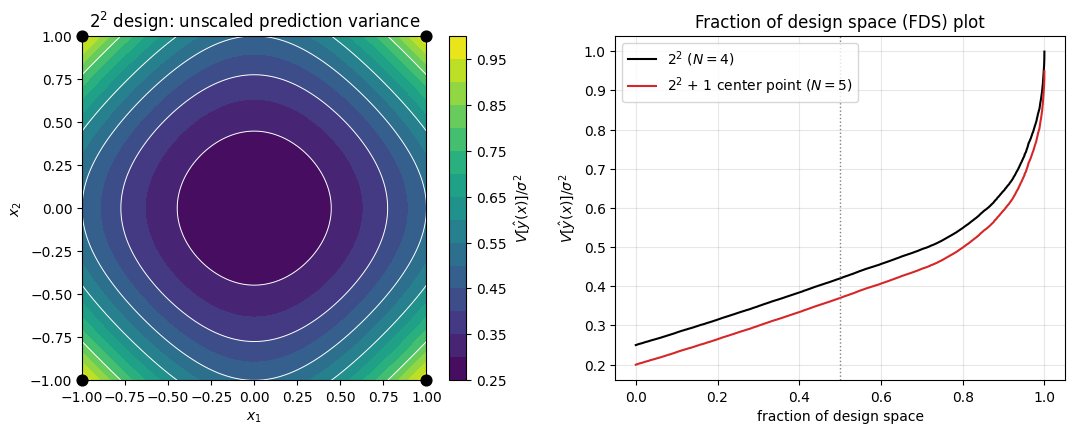

In [4]:
# Figure of Lecture 7: unscaled prediction variance (left) and the fraction of design space plot (right)
rng = np.random.default_rng(1)
u = rng.uniform(-1, 1, size=(20000, 2))          # uniform points in the design region
frac = np.linspace(0, 1, len(u))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
v22 = upv(designs["2^2"], x1, x2)
cs = ax[0].contourf(x1, x2, v22, levels=np.arange(0.25, 1.01, 0.05), cmap="viridis")
ax[0].contour(x1, x2, v22, levels=[0.3, 0.4, 0.5, 0.6, 0.8], colors="w", linewidths=0.7)
ax[0].scatter(*np.array(corners).T, s=60, color="k", clip_on=False, zorder=3)
fig.colorbar(cs, ax=ax[0], label=r"$V[\hat y(x)]/\sigma^2$")
ax[0].set(xlabel="$x_1$", ylabel="$x_2$", aspect="equal", title=r"$2^2$ design: unscaled prediction variance")
for name, lab, col in [("2^2", r"$2^2$ ($N=4$)", "k"), ("2^2 + 1 center", r"$2^2$ + 1 center point ($N=5$)", "tab:red")]:
    v = np.sort(upv(designs[name], u[:, 0], u[:, 1]))
    ax[1].plot(frac, v, color=col, label=lab)
    print(f"{name}: prediction variance <= {np.median(v):.3f} sigma^2 on 50 % of the region")
ax[1].axvline(0.5, color="grey", ls=":", lw=1)
ax[1].set(xlabel="fraction of design space", ylabel=r"$V[\hat y(x)]/\sigma^2$",
          title="Fraction of design space (FDS) plot")
ax[1].legend(loc="upper left")
ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Lecture example: center points in the filtration rate experiment (Example 6.7)

The filtration rate experiment from Exercise 6 (unreplicated $2^4$ design, $A$ temperature, $B$ pressure, $C$ concentration of
formaldehyde, $D$ stirring rate) with **four center points** added: filtration rates 73, 75, 66 and 69 at
$x_1 = x_2 = x_3 = x_4 = 0$. The file contains the 16 factorial runs in standard order followed by the center points.

In [5]:
f = pd.read_csv(URL + "Pilot_Plant_Filtration_Rate_Experiment3.csv", sep=";")
f["cp"] = (f["A"] == 0).astype(int)         # indicator of the center points
f.tail(6)

,A,B,C,D,Rate,cp
14,-1,1,1,1,70,0
15,1,1,1,1,96,0
16,0,0,0,0,73,1
17,0,0,0,0,75,1
18,0,0,0,0,66,1
19,0,0,0,0,69,1


In [6]:
yF = f.loc[f.cp == 0, "Rate"].mean()
yC = f.loc[f.cp == 1, "Rate"].mean()
nF, nC = (f.cp == 0).sum(), (f.cp == 1).sum()
SS_pq = nF * nC * (yF - yC) ** 2 / (nF + nC)          # pure quadratic curvature, 1 df
MS_pe = f.loc[f.cp == 1, "Rate"].var(ddof=1)            # pure error from the center points, nC - 1 df
F0 = SS_pq / MS_pe
t0 = (yF - yC) / np.sqrt(MS_pe * (1 / nF + 1 / nC))
print(f"yF = {yF:.4f}, yC = {yC:.4f}, yF - yC = {yF - yC:.4f}")
print(f"SS_pure quadratic = {SS_pq:.4f}, MS_pure error = {MS_pe:.4f} ({nC - 1} df)")
print(f"F0 = {F0:.4f}, p = {stats.f.sf(F0, 1, nC - 1):.4f}")
print(f"t0 = {t0:.4f}, t0^2 = {t0**2:.4f}, p = {2 * stats.t.sf(abs(t0), nC - 1):.4f}")

yF = 70.0625, yC = 70.7500, yF - yC = -0.6875
SS_pure quadratic = 1.5125, MS_pure error = 16.2500 (3 df)
F0 = 0.0931, p = 0.7802
t0 = -0.3051, t0^2 = 0.0931, p = 0.7802


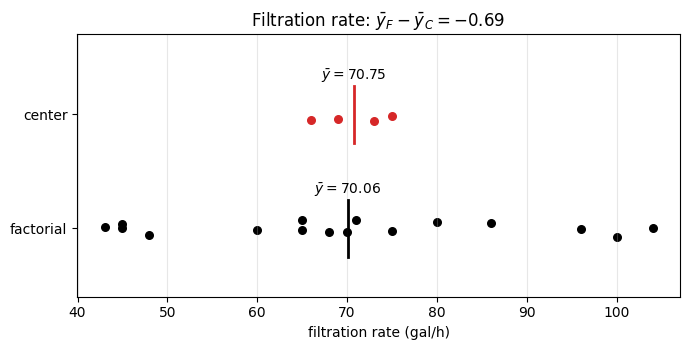

In [7]:
# Figure of Lecture 7: the factorial runs and the center points with their averages
rng = np.random.default_rng(1)
fig, ax = plt.subplots(figsize=(7, 3.6))
for k, (sub, col) in enumerate([(f[f.cp == 0], "k"), (f[f.cp == 1], "tab:red")]):
    ax.scatter(sub.Rate, k + rng.uniform(-0.08, 0.08, len(sub)), color=col, s=30)
    ax.plot([sub.Rate.mean()] * 2, [k - 0.25, k + 0.25], color=col, lw=2)
    ax.annotate(rf"$\bar y = {sub.Rate.mean():.2f}$", (sub.Rate.mean(), k + 0.3), ha="center")
ax.set(yticks=[0, 1], yticklabels=["factorial", "center"], ylim=(-0.6, 1.7), xlabel="filtration rate (gal/h)",
       title=rf"Filtration rate: $\bar y_F - \bar y_C = {yF - yC:.2f}$")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

The averages are very similar, $F_0 = 0.093$ with $1$ and $3$ degrees of freedom ($p = 0.78$): no evidence of pure quadratic
curvature. The $t$-test with $n_C - 1$ degrees of freedom is the same test ($t_0^2 = F_0$).

**Why only the sum $\sum_j \beta_{jj}$?** At the factorial points every $x_j^2 = 1$, at the center $x_j^2 = 0$. All four
columns $x_1^2, \dots, x_4^2$ are identical (and equal to $1 - \texttt{cp}$), so the model matrix of the full second-order
model is rank deficient:

In [8]:
Q = np.column_stack([f[c] ** 2 for c in "ABCD"])
print("identical columns:", all((Q[:, j] == Q[:, 0]).all() for j in range(4)))
print("rank of [x1^2, x2^2, x3^2, x4^2]:", np.linalg.matrix_rank(Q))

identical columns: True
rank of [x1^2, x2^2, x3^2, x4^2]: 1


### Full model with the center-point indicator

Adding the indicator `cp` to the full factorial model separates the curvature sum of squares; the residual is exactly the
pure error from the center points (Montgomery, Table 6.24). Center points do not change any factorial effect estimate.

In [9]:
full = smf.ols("Rate ~ A*B*C*D + cp", data=f).fit()
anova_lm(full).round(4)

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,1870.5625,1870.5625,115.1115,0.0017
B,1.0,39.0625,39.0625,2.4038,0.2188
A:B,1.0,0.0625,0.0625,0.0038,0.9544
C,1.0,390.0625,390.0625,24.0038,0.0163
A:C,1.0,1314.0625,1314.0625,80.8654,0.0029
B:C,1.0,22.5625,22.5625,1.3885,0.3236
A:B:C,1.0,14.0625,14.0625,0.8654,0.4209
D,1.0,855.5625,855.5625,52.6500,0.0054
A:D,1.0,1105.5625,1105.5625,68.0346,0.0037
B:D,1.0,0.5625,0.5625,0.0346,0.8643


### Reduced model, lack of fit and pure error

Keep $A, C, D, AC, AD$ (Exercise 6) and the indicator. The residual of the reduced model consists of the lack of fit
(the omitted factorial effects) and the pure error (center points). The comparison with the full model is the lack-of-fit test.

In [10]:
red = smf.ols("Rate ~ A*C + A*D + cp", data=f).fit()
display(anova_lm(red).round(4))
anova_lm(red, full).round(4)          # lack of fit (10 df) vs pure error (3 df)

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,1870.5625,1870.5625,99.7122,0.0000
C,1.0,390.0625,390.0625,20.7927,0.0005
A:C,1.0,1314.0625,1314.0625,70.0474,0.0000
D,1.0,855.5625,855.5625,45.6066,0.0000
A:D,1.0,1105.5625,1105.5625,58.9331,0.0000
cp,1.0,1.5125,1.5125,0.0806,0.7809
Residual,13.0,243.8750,18.7596,NaN,NaN


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,13.0,243.875,0.0,NaN,NaN,NaN
1,3.0,48.750,10.0,195.125,1.2008,0.4942


In [11]:
# the same reduced model without the indicator: the curvature goes into the residual (14 df)
red0 = smf.ols("Rate ~ A*C + A*D", data=f).fit()
print("SS_E without cp:", round(red0.ssr, 4), " = SS_pq + SS_LOF + SS_PE =",
      round(SS_pq, 4), "+", round(red.ssr - full.ssr, 4), "+", round(full.ssr, 4))

SS_E without cp: 245.3875  = SS_pq + SS_LOF + SS_PE = 1.5125 + 195.125 + 48.75


### Curvature as a regression coefficient

The coefficient of `cp` is $\bar y_C - \bar y_F$, the coefficient of `I(A**2)` is $\bar y_F - \bar y_C$ (any $x_j^2$ gives the
same column). Their $t$-tests use the residual mean square of the reduced model (13 df) instead of the pure error (3 df),
so the $p$-value differs slightly from the $F$-test above.

In [12]:
q = smf.ols("Rate ~ A*C + A*D + I(A**2)", data=f).fit()
pd.DataFrame({"cp model": red.params, "I(A**2) model": q.params.rename({"I(A ** 2)": "cp"})}).round(4)

,cp model,I(A**2) model
Intercept,70.0625,70.7500
A,10.8125,10.8125
C,4.9375,4.9375
A:C,-9.0625,-9.0625
D,7.3125,7.3125
A:D,8.3125,8.3125
cp,0.6875,-0.6875


In [13]:
print("cp:      t =", round(red.tvalues["cp"], 4), " p =", round(red.pvalues["cp"], 4))
print("I(A**2): t =", round(q.tvalues["I(A ** 2)"], 4), " p =", round(q.pvalues["I(A ** 2)"], 4))

cp:      t = 0.2839  p = 0.7809
I(A**2): t = -0.2839  p = 0.7809


If the curvature test were significant, we would augment the design with axial runs and fit the second-order model with a
**central composite design** (Montgomery, Chapter 11).

## 3. Lecture example: blocking a replicated $2^k$ design (Example 7.1)

The chemical process from Exercise 5 ($A$ reactant concentration, $B$ amount of catalyst, $y$ recovery), three replicates of
the $2^2$ design. Only four runs can be made from one batch of raw material, so each replicate is run with a different batch
(block).

In [14]:
chem = pd.DataFrame({
    "A": [-1, 1, -1, 1] * 3,
    "B": [-1, -1, 1, 1] * 3,
    "Block": np.repeat([1, 2, 3], 4),
    "y": [28, 36, 18, 31, 25, 32, 19, 30, 27, 32, 23, 29],
})
chem["Block"] = chem["Block"].astype("category")
print(chem.groupby("Block", observed=True)["y"].sum())
blocked = smf.ols("y ~ Block + A*B", data=chem).fit()
anova_lm(blocked).round(4)

Block
1    113
2    106
3    111
Name: y, dtype: int64


,df,sum_sq,mean_sq,F,PR(>F)
Block,2.0,6.5000,3.2500,0.7852,0.4978
A,1.0,208.3333,208.3333,50.3356,0.0004
B,1.0,75.0000,75.0000,18.1208,0.0053
A:B,1.0,8.3333,8.3333,2.0134,0.2057
Residual,6.0,24.8333,4.1389,NaN,NaN


In [15]:
unblocked = smf.ols("y ~ A*B", data=chem).fit()
print("MS_E with blocks:   ", round(blocked.mse_resid, 4), "on", int(blocked.df_resid), "df")
print("MS_E without blocks:", round(unblocked.mse_resid, 4), "on", int(unblocked.df_resid), "df")

MS_E with blocks:    4.1389 on 6 df
MS_E without blocks: 3.9167 on 8 df


The factorial sums of squares do not change; $SS_{Blocks} = 6.50$ (2 df) is removed from the error. Here the blocks are
small ($MS_{Blocks} = 3.25 < MS_E$) and blocking costs two error degrees of freedom - but we could not know it before the
experiment. The $F$-test for blocks is only an informal comparison (randomization was restricted to within blocks).

## 4. Constructing a $2^k$ design in $2^p$ blocks

### Two blocks: the $2^3$ design with $ABC$ confounded

Method 1 - the table of signs: runs with $ABC = -1$ go to one block, runs with $ABC = +1$ to the other.
Method 2 - the defining contrast $L = x_1 + x_2 + x_3 \pmod 2$ with $x_i \in \{0, 1\}$.

In [16]:
d3 = design_in_blocks(3, ["ABC"])
d3["ABC"] = d3.A * d3.B * d3.C
d3

,A,B,C,label,L,Block,ABC
0,-1,-1,-1,(1),"(0,)",1,-1
1,1,-1,-1,a,"(1,)",2,1
2,-1,1,-1,b,"(1,)",2,1
3,1,1,-1,ab,"(0,)",1,-1
4,-1,-1,1,c,"(1,)",2,1
5,1,-1,1,ac,"(0,)",1,-1
6,-1,1,1,bc,"(0,)",1,-1
7,1,1,1,abc,"(1,)",2,1


In [17]:
for b, grp in d3.groupby("Block"):
    print(f"block {b}:", " ".join(grp.label))
# the main effects and two-factor interactions are balanced within each block
print(d3.groupby("Block")[["A", "B", "C"]].sum())

block 1: (1) ab ac bc
block 2: a b c abc
       A  B  C
Block         
1      0  0  0
2      0  0  0


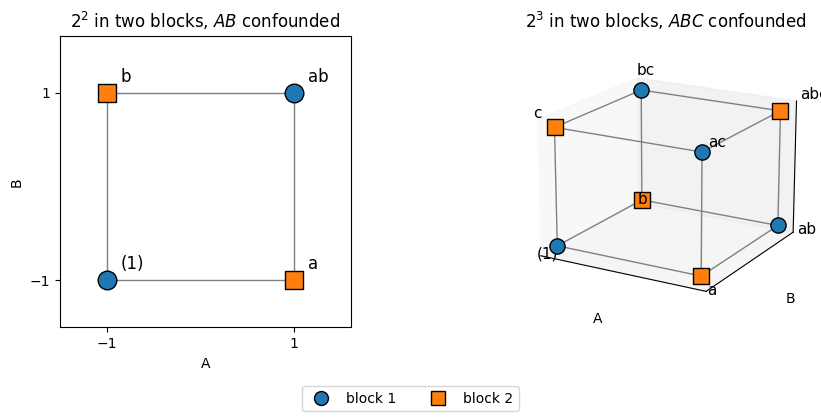

In [18]:
# Figure of Lecture 7: the 2^2 design with AB and the 2^3 design with ABC confounded with blocks
from matplotlib.lines import Line2D
style = {1: dict(marker="o", color="tab:blue"), 2: dict(marker="s", color="tab:orange")}
fig = plt.figure(figsize=(10, 4.2))
a1 = fig.add_subplot(1, 2, 1)
for xa, xb, lab in [(-1, -1, "(1)"), (1, -1, "a"), (-1, 1, "b"), (1, 1, "ab")]:
    a1.scatter(xa, xb, s=180, edgecolor="k", zorder=3, **style[1 if xa * xb > 0 else 2])
    a1.annotate(lab, (xa, xb), xytext=(10, 8), textcoords="offset points", fontsize=12)
a1.plot([-1, 1, 1, -1, -1], [-1, -1, 1, 1, -1], color="grey", lw=1)
a1.set(xlim=(-1.5, 1.6), ylim=(-1.5, 1.6), aspect="equal", xticks=[-1, 1], yticks=[-1, 1], xlabel="A", ylabel="B",
       title=r"$2^2$ in two blocks, $AB$ confounded")
a2 = fig.add_subplot(1, 2, 2, projection="3d")
for e in itertools.product([-1, 1], repeat=3):          # edges of the cube
    for j in range(3):
        if e[j] == -1:
            e2 = list(e)
            e2[j] = 1
            a2.plot(*zip(e, e2), color="grey", lw=1)
for _, r in d3.iterrows():
    a2.scatter(r.A, r.B, r.C, s=120, edgecolor="k", depthshade=False, **style[r.Block])
    a2.text(r.A * 1.18, r.B * 1.18, r.C * 1.18, r.label, fontsize=11)
a2.set(xlabel="A", ylabel="B", zlabel="C", xticks=[], yticks=[], zticks=[],
       title=r"$2^3$ in two blocks, $ABC$ confounded")
a2.view_init(elev=18, azim=-60)
fig.legend(handles=[Line2D([], [], ls="", markeredgecolor="k", ms=10, label=f"block {b}", **style[b]) for b in (1, 2)],
           loc="lower center", ncol=2)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

**Principal block.** The block with $(1)$ is a group under multiplication modulo 2: the product of any two of its runs is
again in the block. The other block is the principal block multiplied by any run not in it.

In [19]:
def run_product(r1, r2):
    s = set(r1.replace("(1)", "")) ^ set(r2.replace("(1)", ""))
    return "".join(sorted(s)) or "(1)"

principal = list(d3.loc[d3.Block == 1, "label"])
print("principal block:", principal)
print("products:", {f"{r1}*{r2}": run_product(r1, r2) for r1, r2 in itertools.combinations(principal, 2)})
print("b * principal block:", [run_product("b", r) for r in principal])

principal block: ['(1)', 'ab', 'ac', 'bc']
products: {'(1)*ab': 'ab', '(1)*ac': 'ac', '(1)*bc': 'bc', 'ab*ac': 'bc', 'ab*bc': 'ac', 'ac*bc': 'ab'}
b * principal block: ['b', 'a', 'abc', 'c']


### Four blocks: the $2^5$ design with $ADE$ and $BCE$ (Section 7.6)

With two generators the third confounded effect is their generalized interaction $(ADE)(BCE) = ABCDE^2 = ABCD$.

In [20]:
gens = ["ADE", "BCE"]
print("confounded with blocks:", confounded_effects(gens))
d5 = design_in_blocks(5, gens)
for b, grp in d5.groupby("Block"):
    print(f"block {b} (L1, L2) = {grp.L.iloc[0]}:", " ".join(grp.label))

confounded with blocks: ['ADE', 'BCE', 'ABCD']
block 1 (L1, L2) = (0, 0): (1) bc ad abcd abe ace bde cde
block 2 (L1, L2) = (0, 1): b c abd acd ae abce de bcde
block 3 (L1, L2) = (1, 0): a abc d bcd be ce abde acde
block 4 (L1, L2) = (1, 1): ab ac bd cd e bce ade abcde


In [21]:
# check: within each block the sign of every confounded effect is constant
for eff in confounded_effects(gens):
    d5[eff] = d5[list(eff)].prod(axis=1)
d5.groupby("Block")[confounded_effects(gens)].agg(["min", "max"])

ADE     BCE     ABCD    
      min max min max  min max
Block                         
1      -1  -1  -1  -1    1   1
2      -1  -1   1   1   -1  -1
3       1   1  -1  -1   -1  -1
4       1   1   1   1    1   1

A bad choice: confounding $ABCDE$ and $ABD$ looks natural, but it also confounds the two-factor interaction $CE$.
For eight blocks of the $2^6$ design (Table 7.9) the generators $ABEF$, $ABCD$, $ACE$ confound $2^3 - 1 = 7$ effects.

In [22]:
print("ABCDE, ABD     ->", confounded_effects(["ABCDE", "ABD"]))
print("ABEF, ABCD, ACE ->", confounded_effects(["ABEF", "ABCD", "ACE"]))

ABCDE, ABD     -> ['ABCDE', 'ABD', 'CE']
ABEF, ABCD, ACE -> ['ABEF', 'ABCD', 'ACE', 'CDEF', 'BCF', 'BDE', 'ADF']


## 5. Lecture example: the filtration rate experiment in two blocks (Example 7.2)

Only eight runs can be made from one batch of raw material, so the $2^4$ design is run in two blocks with $ABCD$
confounded. One batch is of poorer quality: all responses in that block are 20 units lower. We simulate this by subtracting
20 from the original data in the block with $ABCD = +1$.

In [23]:
rate = pd.read_csv(URL + "Pilot_Plant_Filtration_Rate_Experiment.csv", sep=";")
rate["label"] = ["".join(c.lower() for c in "ABCD" if r[c] == 1) or "(1)" for _, r in rate.iterrows()]
rate["Block"] = np.where(rate.A * rate.B * rate.C * rate.D > 0, 1, 2)
rate["y"] = rate.Rate - 20 * (rate.Block == 1)
for b, grp in rate.groupby("Block"):
    print(f"block {b}:", ", ".join(f"{l} = {v}" for l, v in zip(grp.label, grp.y)))

block 1: (1) = 25, ab = 45, ac = 40, bc = 60, ad = 80, bd = 25, cd = 55, abcd = 76
block 2: a = 71, b = 48, c = 68, abc = 65, d = 43, abd = 104, acd = 86, bcd = 70


In [24]:
eff_orig = effects_2k(rate, "Rate", list("ABCD"))
eff_blk = effects_2k(rate, "y", list("ABCD"))
pd.DataFrame({"original": eff_orig.effect, "blocked": eff_blk.effect, "SS blocked": eff_blk.SS})

,original,blocked,SS blocked
term,,,
A,21.625,21.625,1870.5625
B,3.125,3.125,39.0625
A:B,0.125,0.125,0.0625
C,9.875,9.875,390.0625
A:C,-18.125,-18.125,1314.0625
B:C,2.375,2.375,22.5625
A:B:C,1.875,1.875,14.0625
D,14.625,14.625,855.5625
A:D,16.625,16.625,1105.5625


All effects except $ABCD$ are unchanged. The $ABCD$ column estimates the original interaction plus the block effect:
$1.375 + (-20) = -18.625 = \bar y_{\text{block } 1} - \bar y_{\text{block } 2}$, and $SS_{Blocks} = SS_{ABCD} = 1387.56$.

       sum    mean
Block             
1      406  50.750
2      555  69.375


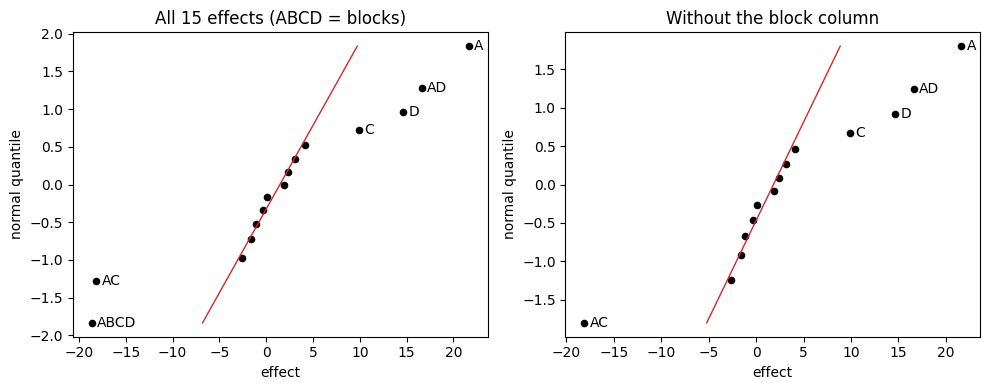

In [25]:
print(rate.groupby("Block")["y"].agg(["sum", "mean"]))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
effect_plot(eff_blk.effect.rename(lambda s: s.replace(":", "")), ax=axes[0], n_label=6, title="All 15 effects (ABCD = blocks)")
effect_plot(eff_blk.effect.drop("A:B:C:D").rename(lambda s: s.replace(":", "")), ax=axes[1],
            title="Without the block column")
plt.tight_layout()
plt.show()

**Python trap.** The formula `y ~ C(Block) + ...` fails with this data frame: the column named `C` hides the patsy function
`C()` that marks a categorical variable. Convert the block to a categorical column instead (or rename the factor column).

In [26]:
rate["Block"] = rate["Block"].astype("category")
m72 = smf.ols("y ~ Block + A*C + A*D", data=rate).fit()
anova_lm(m72).round(4)          # Montgomery, Table 7.7

,df,sum_sq,mean_sq,F,PR(>F)
Block,1.0,1387.5625,1387.5625,66.5808,0.0000
A,1.0,1870.5625,1870.5625,89.7571,0.0000
C,1.0,390.0625,390.0625,18.7168,0.0019
A:C,1.0,1314.0625,1314.0625,63.0540,0.0000
D,1.0,855.5625,855.5625,41.0533,0.0001
A:D,1.0,1105.5625,1105.5625,53.0493,0.0000
Residual,9.0,187.5625,20.8403,NaN,NaN


## 6. Lecture example: why blocking is important (Section 7.5)

Now suppose the design was **not** blocked: the 16 runs were made in random order and the nuisance effect $-20$ affected
the first eight runs. The run order is in Montgomery, Table 7.8.

In [27]:
rate["run_order"] = [8, 11, 1, 3, 9, 12, 2, 13, 7, 6, 16, 5, 14, 15, 10, 4]
rate["y_nb"] = rate.Rate - 20 * (rate.run_order <= 8)
eff_nb = effects_2k(rate, "y_nb", list("ABCD"))
pd.DataFrame({"original": eff_orig.effect, "not blocked": eff_nb.effect}).round(3)

,original,not blocked
term,,
A,21.625,21.625
B,3.125,-1.875
A:B,0.125,-4.875
C,9.875,19.875
A:C,-18.125,-18.125
B:C,2.375,-2.625
A:B:C,1.875,6.875
D,14.625,14.625
A:D,16.625,6.625


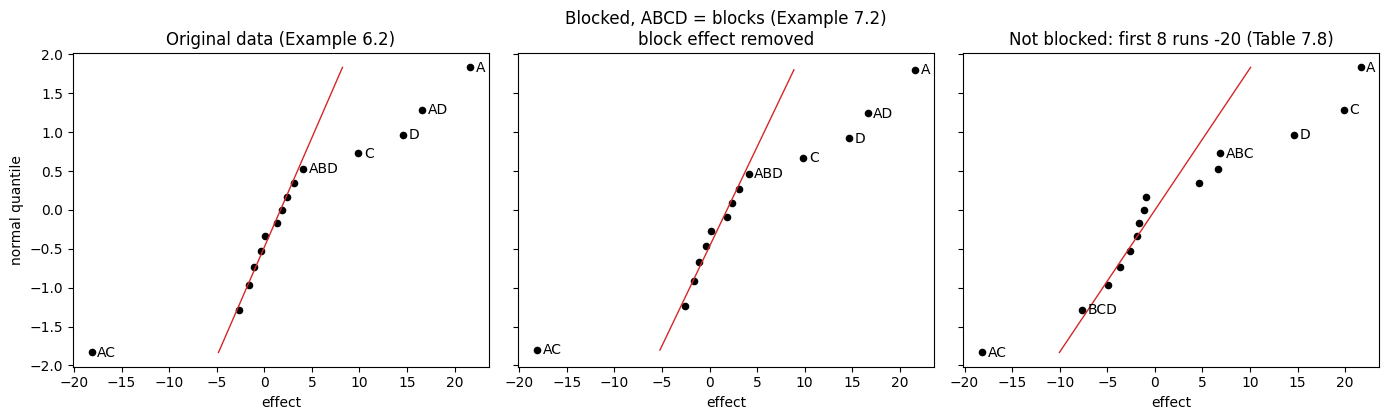

MS_E not blocked (A, C, D, AC): 80.97
MS_E original data (A, C, D, AC, AD): 19.51


In [28]:
# Figure of Lecture 7: normal plots of the effects - original, blocked (Example 7.2), not blocked (Section 7.5)
def short(e):
    return e.rename(lambda s: s.replace(":", ""))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), sharey=True)
effect_plot(short(eff_orig.effect), ax=axes[0], n_label=6, title="Original data (Example 6.2)")
effect_plot(short(eff_blk.effect.drop("A:B:C:D")), ax=axes[1], n_label=6,
            title="Blocked, ABCD = blocks (Example 7.2)\nblock effect removed")
effect_plot(short(eff_nb.effect), ax=axes[2], n_label=6, title="Not blocked: first 8 runs -20 (Table 7.8)")
for ax in axes[1:]:
    ax.set_ylabel("")
plt.tight_layout()
plt.show()
m_nb = smf.ols("y_nb ~ A*C + D", data=rate).fit()
print("MS_E not blocked (A, C, D, AC):", round(m_nb.mse_resid, 2))
print("MS_E original data (A, C, D, AC, AD):", round(smf.ols("Rate ~ A*C + A*D", data=rate).fit().mse_resid, 2))

Without blocking, the important interaction $AD$ drops from $16.6$ to $6.6$ and disappears in the noise, $C$ doubles and
$BCD$ appears. The nuisance variability is spread over the effects whose sign columns are correlated with the indicator of the
first eight runs, and part of it inflates the error. **When in doubt, block.**

## 7. Lecture example: partial confounding (Example 7.3)

The plasma etch experiment from Exercise 5 ($A$ gap, $B$ gas flow, $C$ RF power, etch rate), two replicates of the $2^3$
design. Only four runs can be made in one shift: $ABC$ is confounded in replicate I and $AB$ in replicate II.

In [29]:
plasma = pd.read_csv(URL + "plasma.txt", sep="\t")
pc = pd.concat([plasma.assign(Rep=1, y=plasma.R1), plasma.assign(Rep=2, y=plasma.R2)], ignore_index=True)
pc["Blk"] = np.where(pc.Rep == 1, pc.A * pc.B * pc.C, pc.A * pc.B)   # sign of the confounded effect
pc[["Rep", "Blk"]] = pc[["Rep", "Blk"]].astype("category")
pc.groupby(["Rep", "Blk"], observed=True)["y"].sum()

Rep  Blk
1    -1     3016
      1     3068
2    -1     3182
      1     3151
Name: y, dtype: int64

In [30]:
mp = smf.ols("y ~ Rep + Rep:Blk + A*B*C", data=pc).fit()
anova_lm(mp).round(4)          # sequential (type I): blocks first

,df,sum_sq,mean_sq,F,PR(>F)
Rep,1.0,3875.0625,3875.0625,1.5191,0.2726
Rep:Blk,2.0,458.1250,229.0625,0.0898,0.9156
A,1.0,41310.5625,41310.5625,16.1941,0.0101
B,1.0,217.5625,217.5625,0.0853,0.7820
A:B,1.0,3528.0000,3528.0000,1.3830,0.2925
C,1.0,374850.0625,374850.0625,146.9446,0.0001
A:C,1.0,94402.5625,94402.5625,37.0066,0.0017
B:C,1.0,18.0625,18.0625,0.0071,0.9362
A:B:C,1.0,6.1250,6.1250,0.0024,0.9628
Residual,5.0,12754.8125,2550.9625,NaN,NaN


In [31]:
r1, r2 = pc[pc.Rep == 1], pc[pc.Rep == 2]
ss_ab = ((r1.A * r1.B * r1.y).sum()) ** 2 / 8            # AB only from replicate I
ss_abc = ((r2.A * r2.B * r2.C * r2.y).sum()) ** 2 / 8    # ABC only from replicate II
print("SS_AB (rep I) =", ss_ab, "  SS_ABC (rep II) =", ss_abc)

SS_AB (rep I) = 3528.0   SS_ABC (rep II) = 6.125


The sequential ANOVA with the blocks entered first computes $SS_{AB}$ from replicate I and $SS_{ABC}$ from replicate II
automatically; $SS_{\text{Blocks within replicates}} = 458.125$. The important effects are $A$, $C$ and $AC$, as in
Exercise 5. (Montgomery's Table 7.11 has typos in $SS_C$, $SS_{AC}$ and $SS_E$; the values here agree with Chapter 6.)

## Assignment

Work on the assignment in class (in pairs, if you like). Whatever you do not finish in class, finish at home as homework.

* Run the notebook above and make sure you understand each step.
* Solve the following problems from Montgomery, *Design and Analysis of Experiments* (8th edition): **6.33, the center points
  of 6.31, 6.26 with 6.27, 7.7, 7.8 with 7.9 and 7.24**.
* For every test state the hypotheses, the test statistic, its $p$-value and your decision; end each problem with a
  conclusion in one or two sentences.
* The code is only half of the work. Explain every result in your own words: why you chose the model, what the effects
  mean for the process, what the curvature test or the blocking tells you and what your next step would be. Be ready to
  present and defend your solution of any problem at the beginning of the next exercise.
* Submit your solved notebook as a pull request into the `HW/` folder of the course repository, named
  `HW/01NAEX_Ex07_HW_<Surname>.ipynb` (see `HW/README.md`). **Deadline: Sunday 15 November 2026** (there is no lecture
  on 16 November, the next lecture is on 23 November).

### Problem 6.33

Consider the single replicate of the $2^4$ design in Example 6.2 (filtration rate, `Pilot_Plant_Filtration_Rate_Experiment.csv`).
Suppose that we ran five points at the center $(0, 0, 0, 0)$ and observed the responses 93, 95, 91, 89 and 96. Test for
curvature in this experiment. Interpret the results.

**Solution:**

**Model.** With center runs added to the $2^k$ design the model is
$y = \beta_0 + \sum_j \beta_j x_j + \sum\sum \beta_{ij} x_i x_j + \sum_j \beta_{jj} x_j^2 + \varepsilon$.
All $k$ columns $x_j^2$ equal 1 at the factorial runs and 0 at the center, so they are identical and only their sum
$\sum_j \beta_{jj}$ can be estimated.

**Hypotheses.** $H_0: \sum_j \beta_{jj} = 0$ (no pure quadratic curvature) against $H_1: \sum_j \beta_{jj} \neq 0$.

**Test statistic.** $SS_{PQ} = n_F n_C (\bar y_F - \bar y_C)^2 / (n_F + n_C)$ with 1 degree of freedom, tested against the
pure error of the center points, $F_0 = SS_{PQ} / MS_{PE} \sim F_{1,\, n_C - 1}$ under $H_0$.

In [32]:
# Q6.33: the 2^4 filtration rate experiment with five center points
rate633 = pd.read_csv(URL + "Pilot_Plant_Filtration_Rate_Experiment.csv", sep=";")
d633 = pd.concat([rate633,
                  pd.DataFrame({"A": 0, "B": 0, "C": 0, "D": 0, "Rate": [93.0, 95, 91, 89, 96]})],
                 ignore_index=True)
d633["cp"] = (d633.A == 0).astype(int)

yF, yC = d633.loc[d633.cp == 0, "Rate"], d633.loc[d633.cp == 1, "Rate"]
nF, nC = len(yF), len(yC)
ss_pq = nF * nC * (yF.mean() - yC.mean()) ** 2 / (nF + nC)
ss_pe = ((yC - yC.mean()) ** 2).sum()
ms_pe = ss_pe / (nC - 1)
F0 = ss_pq / ms_pe

print(f"ybar_F = {yF.mean():.4f} ({nF} runs)     ybar_C = {yC.mean():.2f} ({nC} runs)")
print(f"estimate of sum(beta_jj) = ybar_F - ybar_C = {yF.mean() - yC.mean():.4f}")
print(f"SS_PureQuad = {ss_pq:.3f}  (1 df)")
print(f"SS_PE       = {ss_pe:.1f}  ({nC - 1} df)      MS_PE = {ms_pe:.3f}")
print(f"F0 = {F0:.2f}   p = {stats.f.sf(F0, 1, nC - 1):.6f}")

ybar_F = 70.0625 (16 runs)     ybar_C = 92.80 (5 runs)
estimate of sum(beta_jj) = ybar_F - ybar_C = -22.7375
SS_PureQuad = 1969.501  (1 df)
SS_PE       = 32.8  (4 df)      MS_PE = 8.200
F0 = 240.18   p = 0.000101


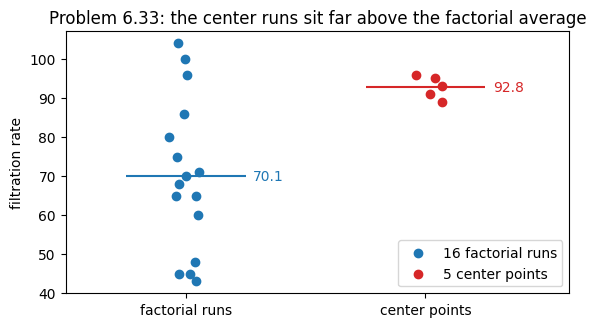

In [33]:
# the same information in a picture
fig, ax = plt.subplots(figsize=(6.5, 3.4))
rng = np.random.default_rng(7)
ax.scatter(rng.uniform(-0.07, 0.07, nF), yF, color="tab:blue", label="16 factorial runs")
ax.scatter(1 + rng.uniform(-0.07, 0.07, nC), yC, color="tab:red", label="5 center points")
ax.hlines(yF.mean(), -0.25, 0.25, color="tab:blue")
ax.hlines(yC.mean(), 0.75, 1.25, color="tab:red")
ax.annotate(f"{yF.mean():.1f}", (0.28, yF.mean()), color="tab:blue", va="center")
ax.annotate(f"{yC.mean():.1f}", (1.28, yC.mean()), color="tab:red", va="center")
ax.set_xticks([0, 1])
ax.set_xticklabels(["factorial runs", "center points"])
ax.set_xlim(-0.5, 1.6)
ax.set_ylabel("filtration rate")
ax.set_title("Problem 6.33: the center runs sit far above the factorial average")
ax.legend(loc="lower right")
plt.show()

**Decision.** $F_0 = 240.18$ with 1 and 4 degrees of freedom gives $p = 0.0001$, so $H_0$ is rejected at any usual level.
The design region contains strong pure quadratic curvature.

**Direction.** $\widehat{\sum_j \beta_{jj}} = \bar y_F - \bar y_C = 70.06 - 92.80 = -22.74$. The sum is negative, so the
response surface bends downwards away from the middle: the five center runs average 92.8 while the sixteen corners average
only 70.1. A maximum lies inside the region, not at a corner.

In [34]:
# Q6.33: the same test as a regression coefficient, plus the lack of fit of the Exercise 6 model
red633 = smf.ols("Rate ~ A*C + A*D + cp", data=d633).fit()
display(anova_lm(red633).round(4))
print("coefficient of cp = ybar_C - ybar_F =", round(red633.params["cp"], 4),
      "  t =", round(red633.tvalues["cp"], 3),
      "  p =", f'{red633.pvalues["cp"]:.2e}')

full633 = smf.ols("Rate ~ A*B*C*D + cp", data=d633).fit()
print("\nlack of fit of the reduced model against the pure error of the center points:")
display(anova_lm(red633, full633).round(4))

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,1870.5625,1870.5625,114.8969,0.0000
C,1.0,390.0625,390.0625,23.9591,0.0002
A:C,1.0,1314.0625,1314.0625,80.7146,0.0000
D,1.0,855.5625,855.5625,52.5518,0.0000
A:D,1.0,1105.5625,1105.5625,67.9078,0.0000
cp,1.0,1969.5006,1969.5006,120.9740,0.0000
Residual,14.0,227.9250,16.2804,NaN,NaN


coefficient of cp = ybar_C - ybar_F = 22.7375   t = 10.999   p = 2.84e-08

lack of fit of the reduced model against the pure error of the center points:


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,14.0,227.925,0.0,NaN,NaN,NaN
1,4.0,32.800,10.0,195.125,2.3796,0.2093


In [35]:
# Q6.33: with a genuine pure error the individual effects can now be tested
eff633 = effects_2k(d633[d633.cp == 0], "Rate", list("ABCD"))
eff633["F0"] = eff633.SS / ms_pe
eff633["p"] = stats.f.sf(eff633.F0, 1, nC - 1)
display(eff633.reindex(eff633.SS.sort_values(ascending=False).index).round(4))

,contrast,effect,SS,coef,F0,p
term,,,,,,
A,173.0,21.625,1870.5625,10.8125,228.1174,0.0001
A:C,-145.0,-18.125,1314.0625,-9.0625,160.2515,0.0002
A:D,133.0,16.625,1105.5625,8.3125,134.8247,0.0003
D,117.0,14.625,855.5625,7.3125,104.3369,0.0005
C,79.0,9.875,390.0625,4.9375,47.5686,0.0023
A:B:D,33.0,4.125,68.0625,2.0625,8.3003,0.0450
B,25.0,3.125,39.0625,1.5625,4.7637,0.0945
B:C:D,-21.0,-2.625,27.5625,-1.3125,3.3613,0.1407
B:C,19.0,2.375,22.5625,1.1875,2.7515,0.1725


**Curvature as a coefficient.** The indicator `cp` has coefficient $\bar y_C - \bar y_F = 22.74$ with $p < 10^{-7}$,
the same test written as a regression ($F_0 = t_0^2$, $SS_{cp} = 1969.5$ in the ANOVA table).

**Lack of fit.** Once the curvature term is in the model, the ten remaining degrees of freedom of the reduced model
$A, C, D, AC, AD$ show no lack of fit, $F = 2.38$ with 10 and 4 df, $p = 0.21$. The reduced model describes the corners
well; what it cannot describe is the interior.

**Effects.** Tested against the 4 df pure error, $A$, $C$, $D$, $AC$ and $AD$ are significant ($p \le 0.0023$) exactly as in
Exercise 6. $ABD$ reaches $p = 0.045$, which is one borderline value out of fifteen tests and has no physical reading, so it
is ignored.

**Conclusions (Problem 6.33)**

* The curvature test rejects $H_0: \sum_j \beta_{jj} = 0$ decisively: $F_0 = 240.18$ on 1 and 4 df, $p = 0.0001$.
* Only $\sum_j \beta_{jj}$ is estimable here. To separate the individual quadratic terms the design must be augmented with
  axial runs, giving a central composite design and a full second order model.
* The active effects stay $A$, $C$, $D$, $AC$, $AD$, now confirmed against a real 4 df error estimate instead of a normal plot.

### Problem 6.31: center points

In Exercise 6 you analyzed the 16 factorial runs of Problem 6.31 (polymer; temperature $A$, catalyst concentration $B$, time
$C$, pressure $D$; responses molecular weight and viscosity). The file `Problem_6_31.txt` also contains **four center points**
(runs 17-20).

In [36]:
p631 = pd.read_csv(URL + "Problem_6_31.txt", sep=";")
p631.tail(6)

,Temperature,Concentration,Time,Pressure,Weight,Viscosity
14,100,8,30,75.0,2500,1500
15,120,8,30,75.0,2710,1600
16,110,6,25,67.5,2515,1500
17,110,6,25,67.5,2500,1460
18,110,6,25,67.5,2400,1525
19,110,6,25,67.5,2475,1500


(a) For both responses estimate the pure error from the center points and test for pure quadratic curvature.

(b) Refit your final models from Exercise 6 with the center points included (coded factors, center points at $0$). Split
the residual into lack of fit and pure error. Is there any lack of fit? Do the conclusions of Problem 6.32 change?

**Solution:**

**Setup.** Code the four factors so that the factorial runs are at $\pm 1$ and the four center runs at $0$:
$x_1 = (T - 110)/10$, $x_2 = (c - 6)/2$, $x_3 = (t - 25)/5$, $x_4 = (p - 67.5)/7.5$.

**Hypotheses (a).** For each response $H_0: \sum_j \beta_{jj} = 0$ against $H_1: \sum_j \beta_{jj} \neq 0$, tested with
$F_0 = SS_{PQ}/MS_{PE}$ on 1 and $n_C - 1 = 3$ degrees of freedom.

In [37]:
# Q6.31 (a): code the factors, split the factorial runs from the center points
p631["A"] = (p631.Temperature - 110) / 10
p631["B"] = (p631.Concentration - 6) / 2
p631["C"] = (p631.Time - 25) / 5
p631["D"] = (p631.Pressure - 67.5) / 7.5
p631["cp"] = (p631.A == 0).astype(int)
fac631, cen631 = p631[p631.cp == 0], p631[p631.cp == 1]
display(cen631[["Temperature", "Concentration", "Time", "Pressure", "Weight", "Viscosity"]])


def curvature_test(fac, cen, response):
    """Pure error from the center points and the test for pure quadratic curvature."""
    nF, nC = len(fac), len(cen)
    mF, mC = fac[response].mean(), cen[response].mean()
    ss_pq = nF * nC * (mF - mC) ** 2 / (nF + nC)
    ss_pe = ((cen[response] - mC) ** 2).sum()
    ms_pe = ss_pe / (nC - 1)
    F0 = ss_pq / ms_pe
    return pd.Series({"ybar_F": mF, "ybar_C": mC, "sum beta_jj": mF - mC, "SS_PQ": ss_pq,
                      "SS_PE": ss_pe, "df_PE": nC - 1, "MS_PE": ms_pe, "F0": F0,
                      "p": stats.f.sf(F0, 1, nC - 1)})


display(pd.DataFrame({r: curvature_test(fac631, cen631, r)
                      for r in ["Weight", "Viscosity"]}).round(4))

,Temperature,Concentration,Time,Pressure,Weight,Viscosity
16,110,6,25,67.5,2515,1500
17,110,6,25,67.5,2500,1460
18,110,6,25,67.5,2400,1525
19,110,6,25,67.5,2475,1500


,Weight,Viscosity
ybar_F,2506.2500,1500.6250
ybar_C,2472.5000,1496.2500
sum beta_jj,33.7500,4.3750
SS_PQ,3645.0000,61.2500
SS_PE,7825.0000,2168.7500
df_PE,3.0000,3.0000
MS_PE,2608.3333,722.9167
F0,1.3974,0.0847
p,0.3223,0.7900


**Decision (a).** Molecular weight: $F_0 = 1.40$ on 1 and 3 df, $p = 0.32$. Viscosity: $F_0 = 0.08$, $p = 0.79$.
Neither response rejects $H_0$, so there is no evidence of pure quadratic curvature in either one.

**Pure error.** The center points give $MS_{PE} = 2608$ for molecular weight and $723$ for viscosity, both on 3 df. The
molecular weight center runs scatter from 2400 to 2515, which is why even a 34 unit gap between the averages is not
significant: the test has little power with only four center runs.

In [38]:
# Q6.31 (b): refit the Exercise 6 models on all 20 runs and split the residual
models631 = {"Weight": "Weight ~ A*B + C", "Viscosity": "Viscosity ~ A + B"}
for resp, formula in models631.items():
    m = smf.ols(formula, data=p631).fit()
    mc = smf.ols(formula + " + cp", data=p631).fit()
    ss_pe = ((cen631[resp] - cen631[resp].mean()) ** 2).sum()
    df_lof = int(m.df_resid) - 3
    ss_lof = m.ssr - ss_pe
    F_lof = (ss_lof / df_lof) / (ss_pe / 3)
    print(f"{resp}:  {formula}   (20 runs, center points at 0)")
    print(m.params.round(4).to_string())
    print(f"  R2 = {m.rsquared:.4f}   MS_E = {m.mse_resid:.1f} on {int(m.df_resid)} df")
    print(f"  SS_E = {m.ssr:.1f} = lack of fit {ss_lof:.1f} ({df_lof} df)"
          f" + pure error {ss_pe:.1f} (3 df)")
    print(f"  F_LOF = {F_lof:.3f}   p = {stats.f.sf(F_lof, df_lof, 3):.4f}")
    print(f"  curvature term: cp = {mc.params['cp']:.3f},  t = {mc.tvalues['cp']:.3f},"
          f"  p = {mc.pvalues['cp']:.4f}\n")

Weight:  Weight ~ A*B + C   (20 runs, center points at 0)
Intercept    2499.500
A              61.875
B              -5.625
A:B            60.000
C             100.625
  R2 = 0.9263   MS_E = 1491.8 on 15 df
  SS_E = 22376.3 = lack of fit 14551.3 (12 df) + pure error 7825.0 (3 df)
  F_LOF = 0.465   p = 0.8530
  curvature term: cp = -33.750,  t = -1.651,  p = 0.1211

Viscosity:  Viscosity ~ A + B   (20 runs, center points at 0)
Intercept    1499.750
A              48.125
B              45.625
  R2 = 0.8175   MS_E = 924.2 on 17 df
  SS_E = 15711.2 = lack of fit 13542.5 (14 df) + pure error 2168.8 (3 df)
  F_LOF = 1.338   p = 0.4583
  curvature term: cp = -4.375,  t = -0.250,  p = 0.8056



lowest viscosity on the design region: 1406 at A = B = -1
molecular weight in [2400, 2500] for C in [-1.000, -0.035]
natural units: 100 C, 4 % catalyst, time 20.0 to 24.8 min, pressure free


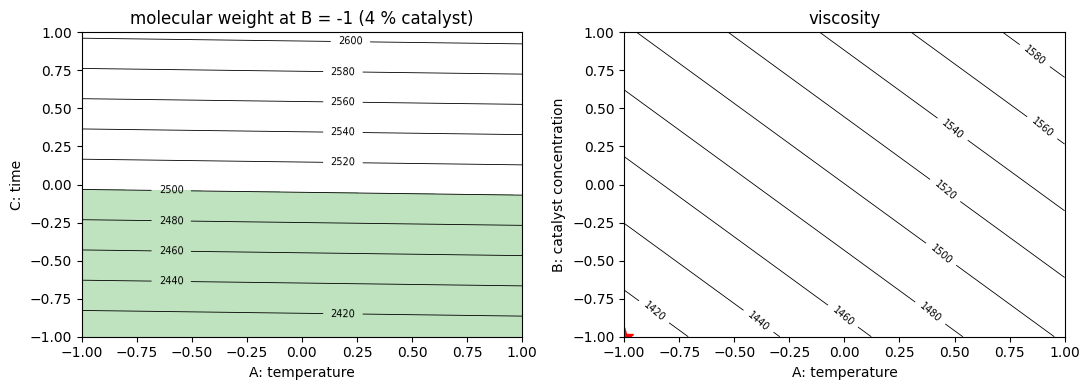

In [39]:
# Q6.31 (b): do the Problem 6.32 recommendations change?
mw631 = smf.ols("Weight ~ A*B + C", data=p631).fit()
vis631 = smf.ols("Viscosity ~ A + B", data=p631).fit()

# viscosity increases in both A and B, so it is smallest at the corner A = B = -1
cgrid = np.linspace(-1, 1, 401)
line = mw631.predict(pd.DataFrame({"A": -1.0, "B": -1.0, "C": cgrid}))
ok = (line >= 2400) & (line <= 2500)
vmin = vis631.predict(pd.DataFrame({"A": [-1.0], "B": [-1.0]})).iloc[0]
print(f"lowest viscosity on the design region: {vmin:.0f} at A = B = -1")
print(f"molecular weight in [2400, 2500] for C in [{cgrid[ok].min():.3f}, {cgrid[ok].max():.3f}]")
print(f"natural units: 100 C, 4 % catalyst, time {25 + 5 * cgrid[ok].min():.1f}"
      f" to {25 + 5 * cgrid[ok].max():.1f} min, pressure free")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
a, c = np.meshgrid(np.linspace(-1, 1, 60), np.linspace(-1, 1, 60))
mw = mw631.predict(pd.DataFrame({"A": a.ravel(), "B": -1.0, "C": c.ravel()})).to_numpy().reshape(a.shape)
cs = axes[0].contour(a, c, mw, levels=12, colors="k", linewidths=0.6)
axes[0].clabel(cs, fontsize=7)
axes[0].contourf(a, c, mw, levels=[2400, 2500], colors=["tab:green"], alpha=0.3)
axes[0].set(xlabel="A: temperature", ylabel="C: time", title="molecular weight at B = -1 (4 % catalyst)")
a2, b2 = np.meshgrid(np.linspace(-1, 1, 60), np.linspace(-1, 1, 60))
vs = vis631.predict(pd.DataFrame({"A": a2.ravel(), "B": b2.ravel()})).to_numpy().reshape(a2.shape)
cs2 = axes[1].contour(a2, b2, vs, levels=10, colors="k", linewidths=0.6)
axes[1].clabel(cs2, fontsize=7)
axes[1].plot(-1, -1, "r*", ms=14)
axes[1].set(xlabel="A: temperature", ylabel="B: catalyst concentration", title="viscosity")
plt.tight_layout()
plt.show()

**Lack of fit (b).** Molecular weight: $SS_E = 22376$ splits into 14551 (12 df) lack of fit and 7825 (3 df) pure error,
$F = 0.46$, $p = 0.85$. Viscosity: 13543 (14 df) against 2169 (3 df), $F = 1.34$, $p = 0.46$. Neither model shows lack of fit,
and the separate curvature terms are also insignificant ($p = 0.12$ and $p = 0.81$).

**Effect of adding the center runs.** The coded factors stay orthogonal to the center runs, so the slopes do not move at all:
molecular weight keeps $\hat y = 2499.5 + 61.9x_1 - 5.6x_2 + 100.6x_3 + 60.0x_1x_2$ and viscosity keeps
$\hat y = 1499.75 + 48.1x_1 + 45.6x_2$. Only the intercepts drop by 6.75 and 0.88, because the center runs came out slightly
below the factorial average.

**Conclusions (Problem 6.31 center points)**

* Neither response shows pure quadratic curvature: $F_0 = 1.40$, $p = 0.32$ for molecular weight and $F_0 = 0.08$,
  $p = 0.79$ for viscosity, both on 1 and 3 df.
* With the center points the residual splits into lack of fit and pure error, and neither model is rejected
  ($p = 0.85$ and $p = 0.46$). The first order models with the $AB$ interaction remain adequate.
* The center runs do not move any slope, only the intercepts (by 6.75 and 0.88), because they are orthogonal to the coded
  factorial columns.
* The Problem 6.32 answer is unchanged: 100 C, 4 % catalyst, 20 to 24.8 min, pressure free, giving viscosity near 1406 and
  molecular weight inside 2400 to 2500.

### Problems 6.26 and 6.27: yield in a semiconductor fabrication plant

An experiment was run in a semiconductor fabrication plant in an effort to increase yield. Five factors, each at two levels,
were studied: $A$ = aperture setting (small, large), $B$ = exposure time (20 % below nominal, 20 % above nominal),
$C$ = development time (30 and 45 s), $D$ = mask dimension (small, large) and $E$ = etch time (14.5 and 15.5 min).
The unreplicated $2^5$ design was run. The file `Ex06_26.csv` contains the 32 runs in standard order (factor levels in
natural units) followed by the four additional runs of Problem 6.27.

In [40]:
p626 = pd.read_csv(URL + "Ex06_26.csv", sep=";")
p626

,Aperture,ExposureTime,DevelopTime,MaskDimension,EtchTime,Yield
0,small,-20,30.0,Small,14.5,7
1,large,-20,30.0,Small,14.5,9
2,small,20,30.0,Small,14.5,34
3,large,20,30.0,Small,14.5,55
4,small,-20,45.0,Small,14.5,16
5,large,-20,45.0,Small,14.5,20
6,small,20,45.0,Small,14.5,40
7,large,20,45.0,Small,14.5,60
8,small,-20,30.0,Large,14.5,8
9,large,-20,30.0,Large,14.5,10


**Problem 6.26** (use the first 32 runs; code the factors to $-1$/$+1$ first)

(a) Construct a normal probability plot of the effect estimates. Which effects appear to be large?

(b) Conduct an analysis of variance to confirm your findings for part (a).

(c) Write down the regression model relating yield to the significant process variables.

(d) Plot the residuals on normal probability paper. Is the plot satisfactory?

(e) Plot the residuals versus the predicted yields and versus each of the five factors. Comment on the plots.

(f) Interpret any significant interactions.

(g) What are your recommendations regarding process operating conditions?

(h) Project the $2^5$ design in this problem into a $2^k$ design in the important factors. Sketch the design and show the
average and range of yields at each run. Does this sketch aid in interpreting the results of this experiment?

**Solution:**

**Coding.** $A$ aperture small/large $\to \mp 1$, $B$ exposure $-20/+20$ % $\to \mp 1$, $C$ development 30/45 s
$\to \mp 1$, $D$ mask small/large $\to \mp 1$, $E$ etch 14.5/15.5 min $\to \mp 1$. Only the first 32 rows are the $2^5$;
the last four rows belong to Problem 6.27.

**Plan.** The design is unreplicated, so there is no error term for the full model. The effects are judged on a normal plot
and with Lenth's method, the negligible ones are pooled into the error, and the resulting model is then tested in the usual way.

In [41]:
# Q6.26 (a): code the factors and compute all 31 effects of the 2^5
def code626(df):
    return pd.DataFrame({
        "A": df.Aperture.map({"small": -1, "large": 1}),
        "B": df.ExposureTime / 20,
        "C": (df.DevelopTime - 37.5) / 7.5,
        "D": df.MaskDimension.map({"Small": -1, "Large": 1}),
        "E": (df.EtchTime - 15.0) / 0.5,
        "Yield": df.Yield.astype(float)})


d626 = code626(p626)
fac626, cen626 = d626.iloc[:32].copy(), d626.iloc[32:].copy()

eff626 = effects_2k(fac626, "Yield", list("ABCDE"))
display(eff626.reindex(eff626.effect.abs().sort_values(ascending=False).index).head(10).round(4))
L626 = lenth(eff626.effect)
print({k: round(v, 4) for k, v in L626.items()})
print("above the margin of error:      ", list(eff626.index[eff626.effect.abs() > L626["ME"]]))
print("above the simultaneous margin:  ", list(eff626.index[eff626.effect.abs() > L626["SME"]]))

,contrast,effect,SS,coef
term,,,,
B,543.0,33.9375,9214.0312,16.9688
A,189.0,11.8125,1116.2812,5.9062
C,155.0,9.6875,750.7812,4.8438
A:B,127.0,7.9375,504.0312,3.9688
D:E,-19.0,-1.1875,11.2812,-0.5938
B:C:D:E,-15.0,-0.9375,7.0312,-0.4688
A:B:D:E,15.0,0.9375,7.0312,0.4688
B:C:E,15.0,0.9375,7.0312,0.4688
A:E,15.0,0.9375,7.0312,0.4688


{'s0': 0.6562, 'PSE': 0.6562, 'ME': 1.4558, 'SME': 2.768}
above the margin of error:       ['A', 'B', 'A:B', 'C']
above the simultaneous margin:   ['A', 'B', 'A:B', 'C']


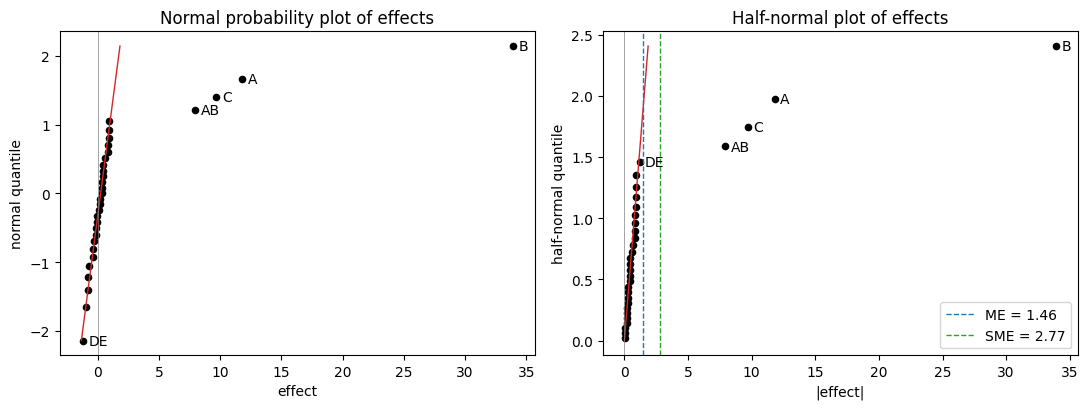

In [42]:
# Q6.26 (a): normal and half-normal plot of the effects
short626 = eff626.effect.rename(lambda s: s.replace(":", ""))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
effect_plot(short626, ax=axes[0])
effect_plot(short626, half=True, ax=axes[1])
for ax in axes:
    ax.axvline(0, color="grey", lw=0.5)
axes[1].axvline(L626["ME"], color="tab:blue", ls="--", lw=1, label=f'ME = {L626["ME"]:.2f}')
axes[1].axvline(L626["SME"], color="tab:green", ls="--", lw=1, label=f'SME = {L626["SME"]:.2f}')
axes[1].legend()
plt.tight_layout()
plt.show()

**(a) Large effects.** Four points leave the straight line: $B$ (33.94), $A$ (11.81), $C$ (9.69) and $AB$ (7.94).
The remaining 27 effects lie on the line through the origin, the largest of them being $DE$ at $-1.19$. Lenth's method agrees:
with $PSE = 0.656$ the margin of error is 1.46 and the simultaneous margin 2.77, and only $A$, $B$, $C$, $AB$ exceed both.
Neither $D$ (mask dimension) nor $E$ (etch time) does anything.

In [43]:
# Q6.26 (b): ANOVA with the 27 negligible effects pooled into the error
m626 = smf.ols("Yield ~ A + B + C + A:B", data=fac626).fit()
display(anova_lm(m626).round(4))
print(f"MS_E = {m626.mse_resid:.4f} on {int(m626.df_resid)} df     R2 = {m626.rsquared:.4f}"
      f"     adj R2 = {m626.rsquared_adj:.4f}")

# the terms that hierarchy or curiosity might add
chk = smf.ols("Yield ~ A*B*C", data=fac626).fit()
print("\nterms left out:",
      {t: round(chk.pvalues[t], 4) for t in ["A:C", "B:C", "A:B:C"]})

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,1116.2812,1116.2812,382.2699,0.0
B,1.0,9214.0313,9214.0313,3155.3401,0.0
C,1.0,750.7812,750.7812,257.1046,0.0
A:B,1.0,504.0313,504.0313,172.6052,0.0
Residual,27.0,78.8438,2.9201,NaN,NaN


MS_E = 2.9201 on 27 df     R2 = 0.9932     adj R2 = 0.9922

terms left out: {'A:C': 0.4928, 'B:C': 0.9216, 'A:B:C': 0.4928}


In [44]:
# Q6.26 (c): the regression model in coded units
print(m626.summary().tables[1])
print("yhat = %.3f + %.3f*x1 + %.3f*x2 + %.3f*x3 + %.3f*x1*x2"
      % tuple(m626.params[["Intercept", "A", "B", "C", "A:B"]]))

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     30.5313      0.302    101.069      0.000      29.911      31.151
A              5.9062      0.302     19.552      0.000       5.286       6.526
B             16.9688      0.302     56.172      0.000      16.349      17.589
C              4.8437      0.302     16.034      0.000       4.224       5.464
A:B            3.9688      0.302     13.138      0.000       3.349       4.589
yhat = 30.531 + 5.906*x1 + 16.969*x2 + 4.844*x3 + 3.969*x1*x2


**(b) ANOVA.** Pooling the 27 negligible effects gives $MS_E = 2.92$ on 27 df. All four retained terms are highly
significant: $B$ with $F_0 = 3155$, $A$ with 382, $C$ with 257 and $AB$ with 173, every $p < 10^{-12}$. The terms left out are
clearly idle ($AC$: $p = 0.48$, $BC$: $p = 0.92$, $ABC$: $p = 0.49$), and the model explains $R^2 = 99.3$ % of the variability.

**(c) Model.** In coded units
$\hat y = 30.53 + 5.91 x_1 + 16.97 x_2 + 4.84 x_3 + 3.97 x_1 x_2$,
where $x_1 = A$, $x_2 = B$, $x_3 = C$. Each coefficient is half of its effect. Hierarchy is respected: all three main effects
below the $AB$ interaction are in the model.

Shapiro-Wilk on the residuals: W = 0.9613, p = 0.2983


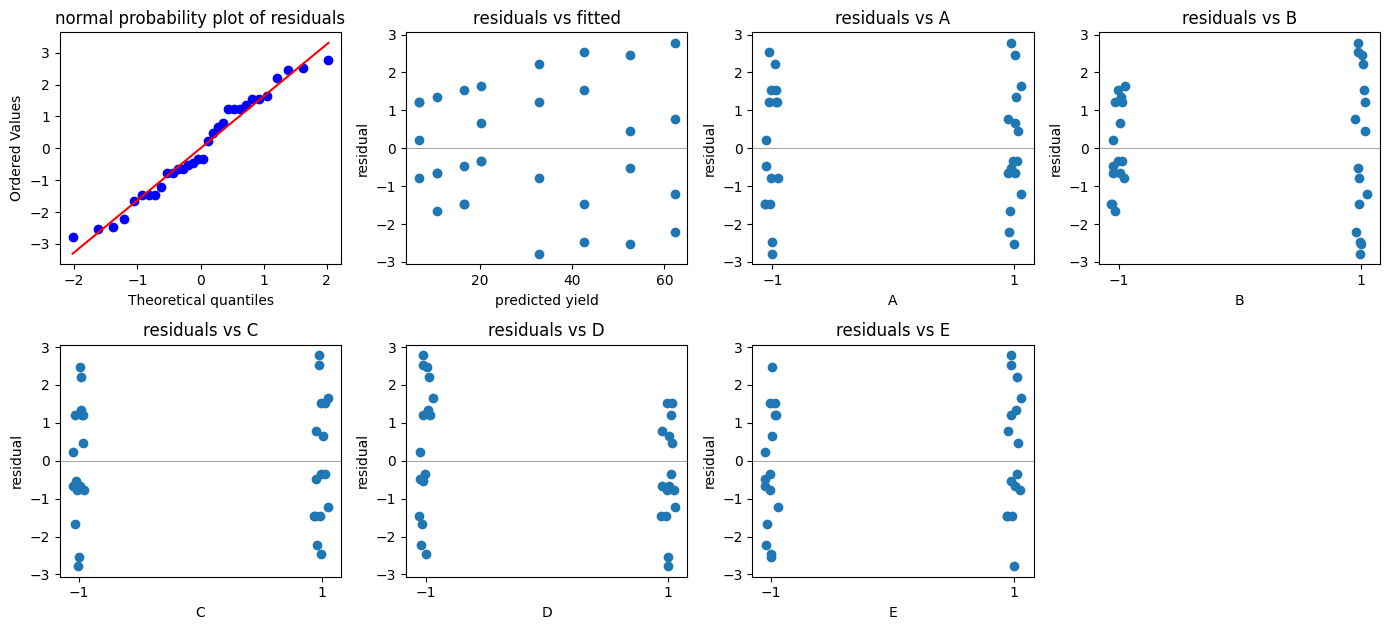


standard deviation of the residuals by level:


,A,B,C,D,E
-1,1.679,1.135,1.566,1.763,1.560
1,1.562,1.992,1.674,1.340,1.649


In [45]:
# Q6.26 (d)(e): residual diagnostics
fac626["fit"] = m626.fittedvalues
fac626["res"] = m626.resid
print("Shapiro-Wilk on the residuals: W = %.4f, p = %.4f" % stats.shapiro(fac626.res))

fig, axes = plt.subplots(2, 4, figsize=(14, 6.4))
stats.probplot(fac626.res, plot=axes[0, 0])
axes[0, 0].set_title("normal probability plot of residuals")
axes[0, 1].scatter(fac626.fit, fac626.res)
axes[0, 1].axhline(0, color="grey", lw=0.5)
axes[0, 1].set(xlabel="predicted yield", ylabel="residual", title="residuals vs fitted")
for ax, col in zip(axes.ravel()[2:], "ABCDE"):
    ax.scatter(fac626[col] + np.random.default_rng(3).uniform(-0.06, 0.06, 32), fac626.res)
    ax.axhline(0, color="grey", lw=0.5)
    ax.set(xlabel=col, ylabel="residual", xticks=[-1, 1], title=f"residuals vs {col}")
axes[1, 3].axis("off")
plt.tight_layout()
plt.show()

print("\nstandard deviation of the residuals by level:")
display(pd.DataFrame({c: fac626.groupby(c).res.std() for c in "ABCDE"}).round(3))

**(d) Normality.** The normal plot of the residuals is close to a straight line and Shapiro-Wilk gives $W = 0.961$,
$p = 0.30$. The plot is satisfactory.

**(e) Residuals against the predictions and the factors.** The residuals are centred at zero everywhere and no factor shows a
pattern in its mean. The spread is not quite constant: at high exposure time the residual standard deviation is 1.99 against
1.14 at low exposure, a mild funnel in the direction of larger yields. With residuals between $-2.78$ and $+2.78$ on yields from
6 to 65 this is minor, so no transformation is applied.

mean   min   max  range
A  B    C                             
-1 -1.0 -1.0   7.25   6.0   8.0    2.0
         1.0  16.00  15.0  18.0    3.0
    1.0 -1.0  32.75  30.0  35.0    5.0
         1.0  42.50  40.0  45.0    5.0
 1 -1.0 -1.0  10.25   9.0  12.0    3.0
         1.0  20.75  20.0  22.0    2.0
    1.0 -1.0  52.50  50.0  55.0    5.0
         1.0  62.25  60.0  65.0    5.0

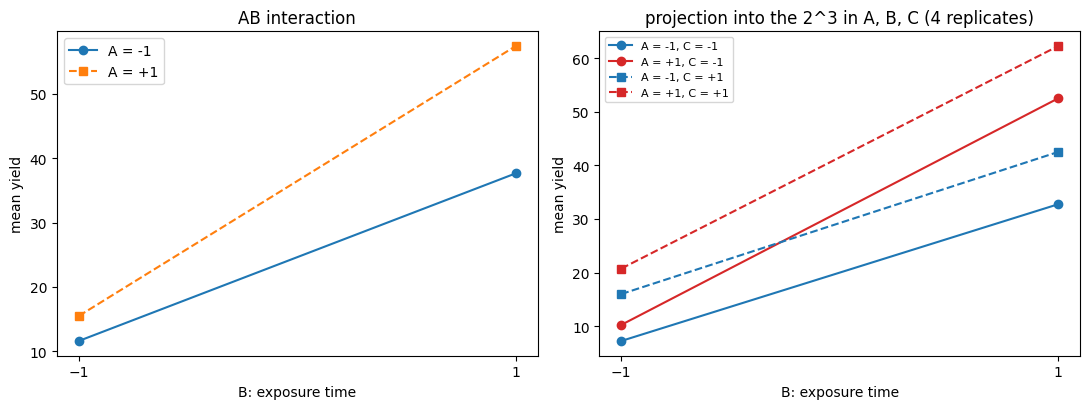

best corner (A, B, C) = (1, 1.0, 1.0)  mean yield = 62.25
predicted yield there = 62.22


In [46]:
# Q6.26 (f)(g)(h): the AB interaction and the projection into the 2^3 in A, B, C
proj = fac626.groupby(["A", "B", "C"]).Yield.agg(["mean", "min", "max"])
proj["range"] = proj["max"] - proj["min"]
display(proj.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for a, style in [(-1, "o-"), (1, "s--")]:
    sub = fac626[fac626.A == a].groupby("B").Yield.mean()
    axes[0].plot(sub.index, sub.values, style, label=f"A = {a:+d}")
axes[0].set(xlabel="B: exposure time", ylabel="mean yield", xticks=[-1, 1],
            title="AB interaction")
axes[0].legend()

cube = proj["mean"].reset_index()
for c, style in [(-1, "o-"), (1, "s--")]:
    for a, col in [(-1, "tab:blue"), (1, "tab:red")]:
        sub = cube[(cube.C == c) & (cube.A == a)]
        axes[1].plot(sub.B, sub["mean"], style, color=col,
                     label=f"A = {a:+d}, C = {c:+d}")
axes[1].set(xlabel="B: exposure time", ylabel="mean yield", xticks=[-1, 1],
            title="projection into the 2^3 in A, B, C (4 replicates)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

best = proj["mean"].idxmax()
print("best corner (A, B, C) =", best, " mean yield =", round(proj["mean"].max(), 2))
print("predicted yield there =",
      round(m626.predict(pd.DataFrame({"A": [best[0]], "B": [best[1]], "C": [best[2]]})).iloc[0], 2))

**(f) Interaction.** $AB$ is positive, so the two factors reinforce each other. Going from low to high exposure time
raises the yield by 26.0 at a small aperture but by 41.9 at a large aperture. Equivalently, the aperture matters only when the
exposure is high: 3.9 units at low exposure against 19.8 at high exposure. The cell means are 11.6, 15.5, 37.6 and 57.4.

**Conclusions (Problem 6.26)**

* Four effects are active: $B$ exposure time (33.94), $A$ aperture (11.81), $C$ development time (9.69) and the $AB$
  interaction (7.94). Lenth's method confirms all four against $ME = 1.46$ and $SME = 2.77$.
* With the other 27 effects pooled, $MS_E = 2.92$ on 27 df and all four terms give $p < 10^{-12}$ with $R^2 = 0.993$.
* The coded model is $\hat y = 30.53 + 5.91x_1 + 16.97x_2 + 4.84x_3 + 3.97x_1x_2$. The residuals are normal
  ($p = 0.30$) with only a mild increase of spread at high yields.
* Mask dimension and etch time are inert, so the design projects into a replicated $2^3$. Best conditions: large aperture,
  exposure $+20$ %, development 45 s, predicted yield 62.2.

**Problem 6.27.** Suppose that the experimenter had run four center points in addition to the 32 trials in the original
experiment. The yields obtained at the center point runs were 68, 74, 76 and 70 (the last four rows of the file).

(a) Reanalyze the experiment, including a test for pure quadratic curvature.

(b) Discuss what your next step would be.

Note: aperture ($A$) and mask dimension ($D$) are qualitative factors. Look at how the four runs are recorded in the file:
each of them has a different combination of $A$ and $D$. Discuss whether their variance can be used as pure error, and
discuss what a "center point" means in this case (Montgomery, Section 6.8, remark 5).

**Solution:**

**Hypotheses.** $H_0: \sum_j \beta_{jj} = 0$ against $H_1: \sum_j \beta_{jj} \neq 0$, with
$F_0 = SS_{PQ}/MS_{PE}$ on 1 and 3 degrees of freedom, where the pure error comes from the four extra runs.

In [47]:
# Q6.27 (a): the four extra runs and the curvature test
display(cen626)
yF626, yC626 = fac626.Yield, cen626.Yield
nF, nC = len(yF626), len(yC626)
ss_pq = nF * nC * (yF626.mean() - yC626.mean()) ** 2 / (nF + nC)
ss_pe = ((yC626 - yC626.mean()) ** 2).sum()
ms_pe = ss_pe / (nC - 1)
F0 = ss_pq / ms_pe
print(f"ybar_F = {yF626.mean():.4f}   ybar_C = {yC626.mean():.2f}"
      f"   difference = {yF626.mean() - yC626.mean():.4f}")
print(f"SS_PureQuad = {ss_pq:.2f} (1 df)")
print(f"SS_PE = {ss_pe:.1f} (3 df)   MS_PE = {ms_pe:.4f}")
print(f"F0 = {F0:.2f}   p = {stats.f.sf(F0, 1, nC - 1):.6f}")

,A,B,C,D,E,Yield
32,-1,0.0,0.0,-1,0.0,68.0
33,1,0.0,0.0,-1,0.0,74.0
34,-1,0.0,0.0,1,0.0,76.0
35,1,0.0,0.0,1,0.0,70.0


ybar_F = 30.5312   ybar_C = 72.00   difference = -41.4688
SS_PureQuad = 6114.34 (1 df)
SS_PE = 40.0 (3 df)   MS_PE = 13.3333
F0 = 458.58   p = 0.000223


In [48]:
# Q6.27 (a): reanalysis of all 36 runs with the center point indicator
all626 = pd.concat([fac626.drop(columns=["fit", "res"]), cen626], ignore_index=True)
all626["cp"] = (all626.B == 0).astype(int)
m627 = smf.ols("Yield ~ A + B + C + A:B + cp", data=all626).fit()
display(anova_lm(m627).round(4))
print(m627.summary().tables[1])

print("\neffects of the 2^5 tested against the 3 df pure error:")
eff627 = effects_2k(fac626, "Yield", list("ABCDE"))
eff627["F0"] = eff627.SS / ms_pe
eff627["p"] = stats.f.sf(eff627.F0, 1, 3)
display(eff627.reindex(eff627.SS.sort_values(ascending=False).index).head(6).round(4))

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,992.2500,992.2500,122.5630,0.0
B,1.0,9214.0312,9214.0312,1138.1202,0.0
C,1.0,750.7813,750.7813,92.7367,0.0
A:B,1.0,504.0312,504.0312,62.2581,0.0
cp,1.0,6114.3368,6114.3368,755.2449,0.0
Residual,30.0,242.8750,8.0958,NaN,NaN


                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     30.5313      0.503     60.700      0.000      29.504      31.558
A              5.2500      0.474     11.071      0.000       4.282       6.218
B             16.9688      0.503     33.736      0.000      15.942      17.996
C              4.8438      0.503      9.630      0.000       3.817       5.871
A:B            3.9688      0.503      7.890      0.000       2.942       4.996
cp            41.4687      1.509     27.482      0.000      38.387      44.550

effects of the 2^5 tested against the 3 df pure error:


,contrast,effect,SS,coef,F0,p
term,,,,,,
B,543.0,33.9375,9214.0312,16.9688,691.0523,0.0001
A,189.0,11.8125,1116.2812,5.9062,83.7211,0.0028
C,155.0,9.6875,750.7812,4.8438,56.3086,0.0049
A:B,127.0,7.9375,504.0312,3.9688,37.8023,0.0087
D:E,-19.0,-1.1875,11.2812,-0.5938,0.8461,0.4255
B:C:D:E,-15.0,-0.9375,7.0312,-0.4688,0.5273,0.5203


the four runs are a 2^2 in the qualitative factors A and D at the center of B, C, E:
  A  contrast =   +0.0   effect =  +0.00   SS =   0.00
  D  contrast =   +4.0   effect =  +2.00   SS =   4.00
  AD contrast =  -12.0   effect =  -6.00   SS =  36.00
  sum of the three SS = 40.0 = SS_PE, so the 3 df of 'pure error' are exactly the A, D and AD effects at the center


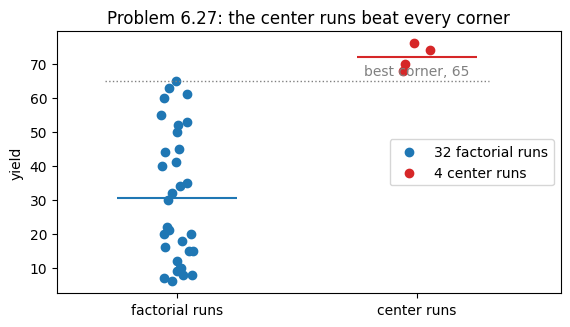

In [49]:
# Q6.27: what the variance of the four "center" runs really measures
print("the four runs are a 2^2 in the qualitative factors A and D at the center of B, C, E:")
for term in ["A", "D", "AD"]:
    contrast = (cen626[list(term)].prod(axis=1) * cen626.Yield).sum()
    print(f"  {term:2s} contrast = {contrast:+6.1f}   effect = {contrast / 2:+6.2f}"
          f"   SS = {contrast ** 2 / 4:6.2f}")
print(f"  sum of the three SS = {ss_pe:.1f} = SS_PE, so the 3 df of 'pure error' are exactly"
      f" the A, D and AD effects at the center")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
rng = np.random.default_rng(11)
ax.scatter(rng.uniform(-0.07, 0.07, nF), yF626, color="tab:blue", label="32 factorial runs")
ax.scatter(1 + rng.uniform(-0.07, 0.07, nC), yC626, color="tab:red", label="4 center runs")
ax.hlines(yF626.mean(), -0.25, 0.25, color="tab:blue")
ax.hlines(yC626.mean(), 0.75, 1.25, color="tab:red")
ax.hlines(fac626.Yield.max(), -0.3, 1.3, color="grey", ls=":", lw=1)
ax.annotate("best corner, 65", (1.0, fac626.Yield.max()), xytext=(0, 4),
            textcoords="offset points", color="grey", ha="center")
ax.set_xticks([0, 1])
ax.set_xticklabels(["factorial runs", "center runs"])
ax.set_xlim(-0.5, 1.6)
ax.set_ylabel("yield")
ax.set_title("Problem 6.27: the center runs beat every corner")
ax.legend(loc="center right")
plt.show()

**Decision.** Significant curvature ($F_0=458.58$, $p=0.0002$) rejects $H_0$, indicating an interior optimum. The estimated curvature is $30.53-72.00=-41.47$.

**Limitations.** The four center runs vary qualitative factors $A,D$, so they do not provide genuine pure error. Nevertheless, the curvature conclusion is robust. Factorial effect estimates should remain unchanged.

**(b) Next step.** Add axial runs in $B,C,E$ to fit a quadratic model. Focus on large aperture ($A$), confirm at small aperture, and replicate center points for pure error.

**Conclusions (Problem 6.27)**

* The curvature test is decisive: $F_0 = 458.58$ on 1 and 3 df, $p = 0.0002$, with $\sum_j \beta_{jj}$ estimated at $-41.5$.
* The center runs (mean 72.0) beat the best corner (65), so the first order model is useless for prediction inside the region
  even though it fits the 32 corners with $R^2 = 0.993$.
* The 3 df of "pure error" are not pure error. They are the $A$, $D$ and $AD$ effects at the center of $B$, $C$, $E$, because
  the two qualitative factors have no middle level. The estimate $MS_{PE} = 13.3$ is therefore conservative.
* Next step: axial runs in the quantitative factors $B$, $C$, $E$ to build a central composite design and fit a second order
  model, run at large aperture, plus replicated center runs for a real error estimate.

### Problem 7.7

Using the data from the $2^5$ design in Problem 6.26, construct and analyze a design in two blocks with $ABCDE$ confounded
with blocks.

**Solution:**

**Construction.** Confounding $ABCDE$ with blocks means the two blocks are the two levels of the $ABCDE$ column.
The principal block holds the runs with $ABCDE = -1$, which is the block containing $(1)$. Each block has 16 runs, and every
main effect and every lower order interaction is balanced inside both blocks.

**Consequence.** Blocks and $ABCDE$ are the same contrast, so $SS_{Blocks} = SS_{ABCDE}$ and the five factor interaction can no
longer be estimated. All other 30 effects are untouched.

In [50]:
# Q7.7: split the 2^5 into two blocks of 16 runs by the sign of ABCDE
blk77 = fac626.drop(columns=["fit", "res"]).copy()
blk77["label"] = ["".join(c.lower() for c in "ABCDE" if r[c] == 1) or "(1)"
                  for _, r in blk77.iterrows()]
blk77["ABCDE"] = blk77[list("ABCDE")].prod(axis=1)
blk77["Block"] = np.where(blk77.ABCDE < 0, 1, 2)

for b, g in blk77.groupby("Block"):
    print(f"block {b} ({len(g)} runs, ABCDE = {int(g.ABCDE.iloc[0]):+d}):",
          " ".join(sorted(g.label, key=lambda s: (len(s), s))))
display(blk77.groupby("Block").Yield.agg(["sum", "mean"]).round(4))

ss_blocks = sum(g.Yield.sum() ** 2 / len(g) for _, g in blk77.groupby("Block")) \
    - blk77.Yield.sum() ** 2 / 32
print(f"SS_Blocks = {ss_blocks:.4f}      SS_ABCDE from the unblocked design ="
      f" {eff626.loc['A:B:C:D:E', 'SS']:.4f}")

block 1 (16 runs, ABCDE = -1): ab ac ad ae bc bd be cd ce de (1) abcd abce abde acde bcde
block 2 (16 runs, ABCDE = +1): a b c d e abc abd abe acd ace ade bcd bce bde cde abcde


,sum,mean
Block,,
1,490.0,30.6250
2,487.0,30.4375


SS_Blocks = 0.2812      SS_ABCDE from the unblocked design = 0.2812


In [51]:
# Q7.7: ANOVA of the blocked design, with the negligible effects pooled as before
blk77["Block"] = blk77.Block.astype("category")
m77 = smf.ols("Yield ~ Block + A + B + C + A:B", data=blk77).fit()
display(anova_lm(m77).round(4))
print(f"MS_E = {m77.mse_resid:.4f} on {int(m77.df_resid)} df"
      f"      (unblocked: {m626.mse_resid:.4f} on {int(m626.df_resid)} df)")

print("\neffect estimates are not changed by blocking:")
display(pd.DataFrame({"unblocked": eff626.effect, "blocked": effects_2k(blk77, "Yield", list("ABCDE")).effect})
        .loc[["A", "B", "C", "A:B", "A:C", "A:B:C:D:E"]].round(4))

,df,sum_sq,mean_sq,F,PR(>F)
Block,1.0,0.2813,0.2813,0.0931,0.7627
A,1.0,1116.2813,1116.2813,369.4296,0.0000
B,1.0,9214.0312,9214.0312,3049.3532,0.0000
C,1.0,750.7812,750.7812,248.4686,0.0000
A:B,1.0,504.0313,504.0313,166.8075,0.0000
Residual,26.0,78.5625,3.0216,NaN,NaN


MS_E = 3.0216 on 26 df      (unblocked: 2.9201 on 27 df)

effect estimates are not changed by blocking:


,unblocked,blocked
term,,
A,11.8125,11.8125
B,33.9375,33.9375
C,9.6875,9.6875
A:B,7.9375,7.9375
A:C,0.4375,0.4375
A:B:C:D:E,-0.1875,-0.1875


**Analysis.** The two block totals are 490 and 487, so $SS_{Blocks} = 0.281$ on 1 df, which is exactly $SS_{ABCDE}$
from the unblocked analysis. Testing it is not meaningful, since the nuisance variable and the interaction cannot be separated,
but the value is tiny: $F = 0.09$, $p = 0.76$.

**Effects.** $A$, $B$, $C$ and $AB$ keep their estimates 11.81, 33.94, 9.69 and 7.94, and the ANOVA conclusions are identical
to Problem 6.26: every $p < 10^{-11}$. The price of blocking is one degree of freedom, $MS_E = 3.02$ on 26 df instead of 2.92 on
27 df.

**Interpretation.** Here the blocks turned out to be almost identical, so blocking cost nothing and gained nothing. Had the two
batches differed, the block contrast would have absorbed the difference and protected the other 30 effects, which is the whole
point of the construction.

### Problems 7.8 and 7.9

**7.8.** Repeat Problem 7.7 assuming that four blocks are necessary. Suggest a reasonable confounding scheme.

**7.9.** Suppose that it was necessary to run the design of Problem 6.26 in four blocks with $ACDE$ and $BCD$ (and
consequently $ABE$) confounded. Analyze the data from this design.

Hint: `confounded_effects()` and `design_in_blocks()` from the setup cell.

**Solution:**

**7.8 Choosing a scheme.** Four blocks need two generators, and their generalized interaction is confounded as well.
A good choice confounds only high order interactions. Taking $ABC$ and $CDE$ gives $(ABC)(CDE) = ABDE$, so two three factor and
one four factor interaction are lost and all main effects and all two factor interactions survive. The alternative
$ADE$, $BCE$, $ABCD$ from the lecture is equally good. A natural looking choice such as $ABCDE$ with $ABD$ must be rejected,
because their product is the two factor interaction $CE$.

In [52]:
# Q7.8: candidate schemes for four blocks
for gens in (["ABC", "CDE"], ["ADE", "BCE"], ["ABCD", "ABE"], ["ABCDE", "ABD"]):
    print(f"{str(gens):26s} -> confounded with blocks: {confounded_effects(gens)}")

gens78 = ["ABC", "CDE"]
d78 = design_in_blocks(5, gens78).merge(blk77[["label", "Yield"]], on="label")
for g in confounded_effects(gens78):
    d78[g] = d78[list(g)].prod(axis=1)
for b, grp in d78.groupby("Block"):
    print(f"\nblock {b} ({len(grp)} runs):",
          " ".join(sorted(grp.label, key=lambda s: (len(s), s))))
    print("   ", {e: int(grp[e].iloc[0]) for e in confounded_effects(gens78)},
          " total =", grp.Yield.sum())

['ABC', 'CDE']             -> confounded with blocks: ['ABC', 'CDE', 'ABDE']
['ADE', 'BCE']             -> confounded with blocks: ['ADE', 'BCE', 'ABCD']
['ABCD', 'ABE']            -> confounded with blocks: ['ABCD', 'ABE', 'CDE']
['ABCDE', 'ABD']           -> confounded with blocks: ['ABCDE', 'ABD', 'CE']

block 1 (8 runs): ab de (1) acd ace bcd bce abde
    {'ABC': -1, 'CDE': -1, 'ABDE': 1}  total = 253.0

block 2 (8 runs): d e ac bc abd abe acde bcde
    {'ABC': -1, 'CDE': 1, 'ABDE': -1}  total = 239.0

block 3 (8 runs): a b cd ce ade bde abcd abce
    {'ABC': 1, 'CDE': -1, 'ABDE': -1}  total = 242.0

block 4 (8 runs): c ad ae bd be abc cde abcde
    {'ABC': 1, 'CDE': 1, 'ABDE': 1}  total = 243.0


In [53]:
# Q7.8: ANOVA of the design in four blocks
ss_b78 = sum(g.Yield.sum() ** 2 / len(g) for _, g in d78.groupby("Block")) - d78.Yield.sum() ** 2 / 32
print(f"SS_Blocks (3 df) = {ss_b78:.4f} = sum of the confounded effects:",
      {e: round(eff626.loc[":".join(e), "SS"], 4) for e in confounded_effects(gens78)})

d78["Block"] = d78.Block.astype("category")
m78 = smf.ols("Yield ~ Block + A + B + C + A:B", data=d78).fit()
display(anova_lm(m78).round(4))
print(f"MS_E = {m78.mse_resid:.4f} on {int(m78.df_resid)} df")

SS_Blocks (3 df) = 13.8438 = sum of the confounded effects: {'ABC': 1.5312, 'CDE': 5.2812, 'ABDE': 7.0312}


,df,sum_sq,mean_sq,F,PR(>F)
Block,3.0,13.8438,4.6146,1.7038,0.1929
A,1.0,1116.2812,1116.2812,412.1654,0.0000
B,1.0,9214.0312,9214.0312,3402.1038,0.0000
C,1.0,750.7812,750.7812,277.2115,0.0000
A:B,1.0,504.0312,504.0312,186.1038,0.0000
Residual,24.0,65.0000,2.7083,NaN,NaN


MS_E = 2.7083 on 24 df


In [54]:
# Q7.9: four blocks with ACDE and BCD, and consequently ABE, confounded
gens79 = ["ACDE", "BCD"]
print("confounded with blocks:", confounded_effects(gens79))
d79 = design_in_blocks(5, gens79).merge(blk77[["label", "Yield"]], on="label")
for b, grp in d79.groupby("Block"):
    print(f"block {b} ({len(grp)} runs):",
          " ".join(sorted(grp.label, key=lambda s: (len(s), s))), " total =", grp.Yield.sum())

ss_b79 = sum(g.Yield.sum() ** 2 / len(g) for _, g in d79.groupby("Block")) - d79.Yield.sum() ** 2 / 32
print(f"\nSS_Blocks (3 df) = {ss_b79:.4f} = ",
      {e: round(eff626.loc[":".join(e), "SS"], 4) for e in confounded_effects(gens79)})

d79["Block"] = d79.Block.astype("category")
m79 = smf.ols("Yield ~ Block + A + B + C + A:B", data=d79).fit()
display(anova_lm(m79).round(4))
print(f"MS_E = {m79.mse_resid:.4f} on {int(m79.df_resid)} df")

confounded with blocks: ['ACDE', 'BCD', 'ABE']
block 1 (8 runs): ae cd (1) abc abd bce bde acde  total = 242.0
block 2 (8 runs): b ac ad ce de abe bcd abcde  total = 244.0
block 3 (8 runs): a e bc bd acd cde abce abde  total = 243.0
block 4 (8 runs): c d ab be ace ade abcd bcde  total = 248.0

SS_Blocks (3 df) = 2.5938 =  {'ACDE': 0.7812, 'BCD': 1.5312, 'ABE': 0.2812}


,df,sum_sq,mean_sq,F,PR(>F)
Block,3.0,2.5937,0.8646,0.2721,0.8449
A,1.0,1116.2812,1116.2812,351.3541,0.0000
B,1.0,9214.0313,9214.0313,2900.1541,0.0000
C,1.0,750.7812,750.7812,236.3115,0.0000
A:B,1.0,504.0313,504.0313,158.6459,0.0000
Residual,24.0,76.2500,3.1771,NaN,NaN


MS_E = 3.1771 on 24 df


In [55]:
# Q7.7 to 7.9: the four analyses side by side
rows = []
for name, model, conf in [("unblocked (6.26)", m626, []),
                          ("2 blocks, ABCDE (7.7)", m77, ["ABCDE"]),
                          ("4 blocks, ABC CDE (7.8)", m78, confounded_effects(gens78)),
                          ("4 blocks, ACDE BCD (7.9)", m79, confounded_effects(gens79))]:
    rows.append({"design": name, "block size": 32 // max(len(conf) + 1, 1),
                 "confounded": ", ".join(conf) or "-",
                 "MS_E": round(model.mse_resid, 4), "df_E": int(model.df_resid),
                 "A": round(model.params["A"] * 2, 3), "B": round(model.params["B"] * 2, 3),
                 "C": round(model.params["C"] * 2, 3), "AB": round(model.params["A:B"] * 2, 3)})
display(pd.DataFrame(rows).set_index("design"))

,block size,confounded,MS_E,df_E,A,B,C,AB
design,,,,,,,,
unblocked (6.26),32,-,2.9201,27,11.812,33.938,9.687,7.938
"2 blocks, ABCDE (7.7)",16,ABCDE,3.0216,26,11.813,33.938,9.687,7.938
"4 blocks, ABC CDE (7.8)",8,"ABC, CDE, ABDE",2.7083,24,11.813,33.937,9.688,7.938
"4 blocks, ACDE BCD (7.9)",8,"ACDE, BCD, ABE",3.1771,24,11.812,33.938,9.687,7.938


**7.8 Analysis.** The four blocks are the four sign combinations of $ABC$ and $CDE$, eight runs each. Their sums of
squares add up to $SS_{Blocks} = 13.84$ on 3 df, which is exactly $SS_{ABC} + SS_{CDE} + SS_{ABDE} = 1.53 + 5.28 + 7.03$. The
block term is not significant, $F = 1.70$, $p = 0.19$. The four active effects keep their estimates and their $p$ values below
$10^{-11}$, and $MS_E = 2.71$ on 24 df.

**7.9 Analysis.** The generators $ACDE$ and $BCD$ give $(ACDE)(BCD) = ABE$, so the confounded set is $ACDE$, $BCD$, $ABE$:
again no main effect and no two factor interaction is lost, so this is also an acceptable scheme. Here
$SS_{Blocks} = 2.59$ on 3 df, $F = 0.27$, $p = 0.84$, and $MS_E = 3.18$ on 24 df.

**Comparison.** The effect estimates are identical in all four analyses, because blocking only removes whole contrasts and the
design stays orthogonal. What differs is the error: 2.92 on 27 df unblocked, 3.02 on 26 df with two blocks, 2.71 and 3.18 on
24 df with four blocks. The differences are noise, since the real block effects in this data set are negligible. In a real
experiment the gain comes from smaller, more homogeneous blocks, paid for with the confounded high order interactions.

**Conclusions (Problems 7.7, 7.8 and 7.9)**

* Confounding $ABCDE$ splits the $2^5$ into two blocks of 16 with $SS_{Blocks} = SS_{ABCDE} = 0.281$. Only the five factor
  interaction is lost and the conclusions of Problem 6.26 are unchanged.
* For four blocks $ABC$ and $CDE$ (hence $ABDE$) is a reasonable scheme: blocks of eight runs, no main effect and no two factor
  interaction confounded, $SS_{Blocks} = 13.84$ on 3 df, $p = 0.19$.
* The scheme $ABCDE$ with $ABD$ must be avoided, since their generalized interaction is the two factor interaction $CE$.
* The scheme of Problem 7.9, $ACDE$ and $BCD$ with $ABE$, is equally acceptable: $SS_{Blocks} = 2.59$ on 3 df, $p = 0.84$.
* In every version $A$, $B$, $C$ and $AB$ are significant with the same estimates 11.81, 33.94, 9.69 and 7.94. Blocking costs
  one degree of freedom per block and protects the remaining effects against the nuisance factor.

### Problem 7.24: partial confounding

Problem 6.1: an engineer is interested in the effects of cutting speed ($A$), tool geometry ($B$) and cutting angle ($C$) on the
life (in hours) of a machine tool. Three replicates of the $2^3$ design were run. The file `Problem_6_1.txt` lists the three
replicates (I, II, III) of each treatment combination one after another.

In [56]:
p61 = pd.read_csv(URL + "Problem_6_1.txt", sep=";")
p61.head(6)

,CuttingSpeed,ToolGeometry,CuttingAngle,LifeHours
0,-1,-1,-1,22
1,-1,-1,-1,31
2,-1,-1,-1,25
3,1,-1,-1,32
4,1,-1,-1,43
5,1,-1,-1,29


Suppose that in Problem 6.1 we had confounded $ABC$ in replicate I, $AB$ in replicate II and $BC$ in replicate III (each
replicate run in two blocks of four runs). Calculate the factor effect estimates. Construct the analysis of variance table.
Compare the results with the analysis of the unconfounded design (each replicate a block).

**Solution:**

**Design.** Each replicate of the $2^3$ is run in two blocks of four, and a different interaction is confounded in
each replicate: $ABC$ in replicate I, $AB$ in replicate II, $BC$ in replicate III. Inside one replicate the confounded effect
cannot be separated from the block difference, but it is clean in the other two, so every effect is estimable from part of the
data. This is partial confounding.

**Estimates.** $A$, $B$, $C$ and $AC$ are never confounded and use all 24 observations. $AB$ comes from replicates I and III,
$BC$ from I and II, $ABC$ from II and III, each from 16 observations only, so their variance is $3/2$ times larger and their
standard error $\sqrt{1.5} = 1.22$ times larger. The relative information on them is $2/3$.

**ANOVA.** Degrees of freedom: replicates 2, blocks within replicates 3, the seven factorial effects 7, error 11, total 23. With
the blocks entered first, the sequential sums of squares of the partially confounded effects are computed automatically from
their unconfounded replicates.

In [57]:
# Q7.24: assign the replicates and build the blocks of the partially confounded design
p724 = pd.DataFrame({"A": p61.CuttingSpeed, "B": p61.ToolGeometry, "C": p61.CuttingAngle,
                     "y": p61.LifeHours.astype(float)})
p724["Rep"] = [i % 3 + 1 for i in range(len(p724))]       # the file lists I, II, III per run
conf724 = {1: "ABC", 2: "AB", 3: "BC"}
p724["confounded"] = p724.Rep.map(conf724)
p724["sign"] = 1
for r, term in conf724.items():
    mask = p724.Rep == r
    p724.loc[mask, "sign"] = p724.loc[mask, list(term)].prod(axis=1)
p724["Blk"] = np.where(p724["sign"] < 0, 1, 2)
p724["label"] = ["".join(c.lower() for c in "ABC" if r[c] == 1) or "(1)"
                 for _, r in p724.iterrows()]

for (r, b), g in p724.groupby(["Rep", "Blk"]):
    print(f"replicate {r}, block {b}  [{conf724[r]} = {int(g['sign'].iloc[0]):+d}]:"
          f"  {' '.join(sorted(g.label))}   total = {g.y.sum():.0f}")

replicate 1, block 1  [ABC = -1]:  (1) ab ac bc   total = 177
replicate 1, block 2  [ABC = +1]:  a abc b c   total = 150
replicate 2, block 1  [AB = -1]:  a ac b bc   total = 164
replicate 2, block 2  [AB = +1]:  (1) ab abc c   total = 164
replicate 3, block 1  [BC = -1]:  ab ac b c   total = 170
replicate 3, block 2  [BC = +1]:  (1) a abc bc   total = 155


In [58]:
# Q7.24: effect estimates from the replicates in which each effect is not confounded
rows = []
for r in range(1, 4):
    for comb in itertools.combinations("ABC", r):
        term = "".join(comb)
        reps = [rr for rr in (1, 2, 3) if conf724[rr] != term]
        sub = p724[p724.Rep.isin(reps)]
        contrast = (sub[list(term)].prod(axis=1) * sub.y).sum()
        rows.append({"term": term, "replicates used": "".join(map(str, reps)),
                     "contrast": contrast, "effect": contrast / (len(reps) * 4),
                     "SS": contrast ** 2 / (len(reps) * 8),
                     "effect if nothing confounded": (p724[list(term)].prod(axis=1) * p724.y).sum() / 12})
display(pd.DataFrame(rows).set_index("term").round(4))

print("sums of squares of the confounded effects inside their own replicate"
      " (= blocks within replicates):")
tot = 0.0
for r in (1, 2, 3):
    sub = p724[p724.Rep == r]
    term = conf724[r]
    ss = (sub[list(term)].prod(axis=1) * sub.y).sum() ** 2 / 8
    tot += ss
    print(f"  {term} in replicate {r}: SS = {ss:.4f}")
print(f"  total = {tot:.4f} on 3 df")

,replicates used,contrast,effect,SS,effect if nothing confounded
term,,,,,
A,123,4.0,0.3333,0.6667,0.3333
B,123,136.0,11.3333,770.6667,11.3333
C,123,82.0,6.8333,280.1667,6.8333
AB,13,-20.0,-2.5000,25.0000,-1.6667
AC,123,-106.0,-8.8333,468.1667,-8.8333
BC,12,-19.0,-2.3750,22.5625,-2.8333
ABC,23,1.0,0.1250,0.0625,-2.1667


sums of squares of the confounded effects inside their own replicate (= blocks within replicates):
  ABC in replicate 1: SS = 91.1250
  AB in replicate 2: SS = 0.0000
  BC in replicate 3: SS = 28.1250
  total = 119.2500 on 3 df


In [59]:
# Q7.24: ANOVA of the partially confounded design, blocks entered first
p724["Repc"] = p724.Rep.astype("category")
p724["Blkc"] = p724.Blk.astype("category")
m724 = smf.ols("y ~ Repc + Repc:Blkc + A*B*C", data=p724).fit()
display(anova_lm(m724).round(4))
print(f"MS_E = {m724.mse_resid:.4f} on {int(m724.df_resid)} df")

print("\nthe same data analyzed as an unconfounded design, each replicate one block:")
m724u = smf.ols("y ~ Repc + A*B*C", data=p724).fit()
display(anova_lm(m724u).round(4))
print(f"MS_E = {m724u.mse_resid:.4f} on {int(m724u.df_resid)} df")

,df,sum_sq,mean_sq,F,PR(>F)
Repc,2.0,0.5833,0.2917,0.0079,0.9922
Repc:Blkc,3.0,119.2500,39.7500,1.0711,0.4010
A,1.0,0.6667,0.6667,0.0180,0.8958
B,1.0,770.6667,770.6667,20.7672,0.0008
A:B,1.0,25.0000,25.0000,0.6737,0.4292
C,1.0,280.1667,280.1667,7.5497,0.0190
A:C,1.0,468.1667,468.1667,12.6157,0.0045
B:C,1.0,22.5625,22.5625,0.6080,0.4520
A:B:C,1.0,0.0625,0.0625,0.0017,0.9680
Residual,11.0,408.2083,37.1098,NaN,NaN


MS_E = 37.1098 on 11 df

the same data analyzed as an unconfounded design, each replicate one block:


,df,sum_sq,mean_sq,F,PR(>F)
Repc,2.0,0.5833,0.2917,0.0085,0.9916
A,1.0,0.6667,0.6667,0.0194,0.8913
B,1.0,770.6667,770.6667,22.3806,0.0003
A:B,1.0,16.6667,16.6667,0.4840,0.4980
C,1.0,280.1667,280.1667,8.1362,0.0128
A:C,1.0,468.1667,468.1667,13.5959,0.0024
B:C,1.0,48.1667,48.1667,1.3988,0.2566
A:B:C,1.0,28.1667,28.1667,0.8180,0.3811
Residual,14.0,482.0833,34.4345,NaN,NaN


MS_E = 34.4345 on 14 df


**Estimates.** The effects are $A=0.33$, $B=11.33$, $C=6.83$, $AB=-2.50$, $AC=-8.83$, $BC=-2.38$, $ABC=0.13$. Partially confounded effects use only two replicates.

**Block sums of squares.** Confounded contrasts contribute $91.13$, $0.00$ and $28.13$, giving $SS_{\text{blocks}}=119.25$ on 3 df.

**Tests.** Significant effects are $B$ ($p=0.0008$), $AC$ ($p=0.0045$) and $C$ ($p=0.019$). All other effects and blocks are insignificant ($p\geq0.40$).

**Comparison.** Both designs yield identical conclusions. Partial confounding reduces error df from 14 to 11 and increases $MS_E$ from 34.43 to 37.11, but permits blocks of four instead of eight runs.

**Conclusions (Problem 7.24).** All effects remain estimable, although three use only $2/3$ of the information. Tool geometry ($B$), cutting angle ($C$) and interaction $AC$ significantly affect tool life. Partial confounding trades some precision for smaller blocks.